### Importando bibliotecas

In [1]:
# Carregamento de dados
from joblib import load, dump
import os

# Processamento de dados
import numpy as np
import pandas as pd

# Graficos
import seaborn as sns
import matplotlib.pyplot as plt

# Funções de clustering
from src.clustering import Clustering

In [2]:
#Modelos de aprendizado de máquina
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score, StratifiedKFold
from scipy.stats import chisquare
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.metrics import adjusted_rand_score

## Cross Validation and Grid Search

In [3]:
#Validação cruzada K-Fold
data = load_iris()
X, y = data.data, data.target

model = LogisticRegression(max_iter=200)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=kfold, scoring="accuracy")

print(f"Scores per fold: {scores}")
print(f"Mean Accuracy: {np.mean(scores):.4f}")
print(f"Standard Deviation: {np.std(scores):.4f}")

Scores per fold: [1.         1.         0.93333333 0.96666667 0.96666667]
Mean Accuracy: 0.9733
Standard Deviation: 0.0249


In [4]:
#Validação cruzada estratificada
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=kfold, scoring="accuracy")

print(f"Scores per fold: {scores}")
print(f"Mean Accuracy: {np.mean(scores):.4f}")
print(f"Standard Deviation: {np.std(scores):.4f}")


Scores per fold: [1.         0.96666667 0.93333333 1.         0.93333333]
Mean Accuracy: 0.9667
Standard Deviation: 0.0298


In [5]:
#Identificando arquivos de treino e teste
os.listdir("tabelas/tabelas_finais")

FileNotFoundError: [Errno 2] No such file or directory: 'tabelas/tabelas_finais'

In [ ]:
#Concatenando tabelas de treino
df_train = pd.concat(
    [
        pd.read_csv("tabelas/tabelas_finais/X_train.csv"),
        pd.read_csv("tabelas/tabelas_finais/y_train.csv"),
    ],
    axis=1,
)

In [ ]:
#Concatenando tabelas de teste
df_test = pd.concat(
    [
        pd.read_csv("tabelas/tabelas_finais/X_test.csv"),
        pd.read_csv("tabelas/tabelas_finais/y_test.csv"),
    ],
    axis=1,
)

### Validação cruzada e busca de hiperparâmetros

# K-Means

## Treino

In [ ]:
#Definindo um objeto com os dados de treino
nome_modelo = "kmeans"
bivariadas =  [
        ['n_tetraciclina', 'n_polimixinas'],
        ['n_tetraciclina', 'n_degradacao_aromaticos'],
        ['n_polimixinas', 'n_degradacao_aromaticos']
]
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

array([0, 0, 0, 0, 1], dtype=int32)

In [ ]:
#Obtendo as métricas de avaliação para todas as combinações
data = {}
for i in df_train.columns[:-1]:
    for j in df_train.columns[:-1]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas.head()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_c

In [ ]:
#Selecionando as melhores combinações de variáveis
display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nsmallest(1))
display(df_metricas["Davies Bouldin"].nlargest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

n_OXA_n_MBL    1.0
Name: Silhouette, dtype: float64

n_OXA_n_sulfa_trimetoprim    1178.454
Name: Calinski Harabasz, dtype: float64

n_ISAba1_n_aminoglicosideos    0.71
Name: Davies Bouldin, dtype: float64

n_tetraciclina_n_polimixinas    0.723
Name: Adjusted Rand, dtype: float64

n_tetraciclina_n_ilha_AbaR    0.628
Name: Adjusted Mutual Info, dtype: float64

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.869472497498417e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.723
Adjusted Mutual Info Score -> 0.597


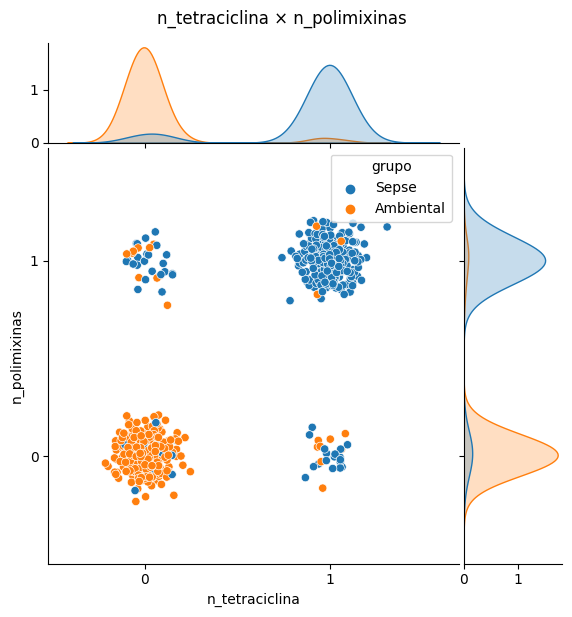

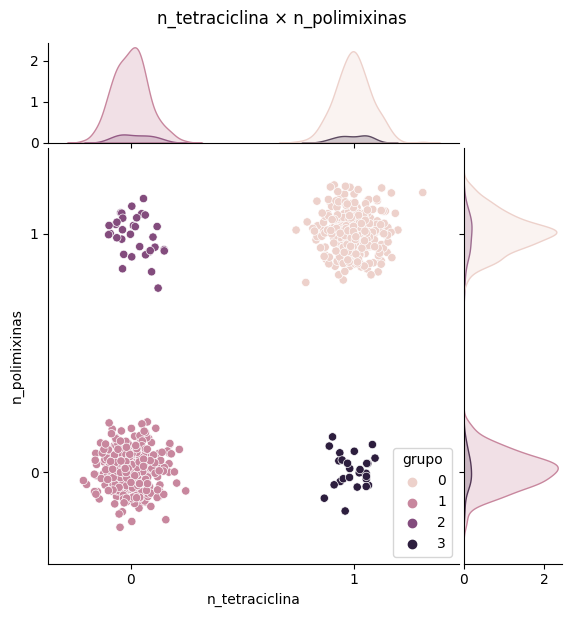

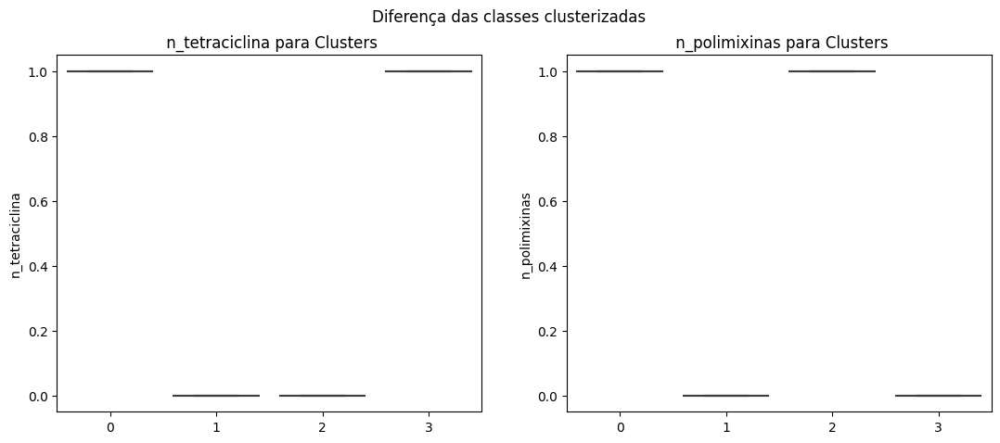

In [ ]:
#Avaliando entre n_tetraciclina e n_polimixinas
i = bivariadas[0][0]
j = bivariadas[0][1]

cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.2031311635893638e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.683
Adjusted Mutual Info Score -> 0.628


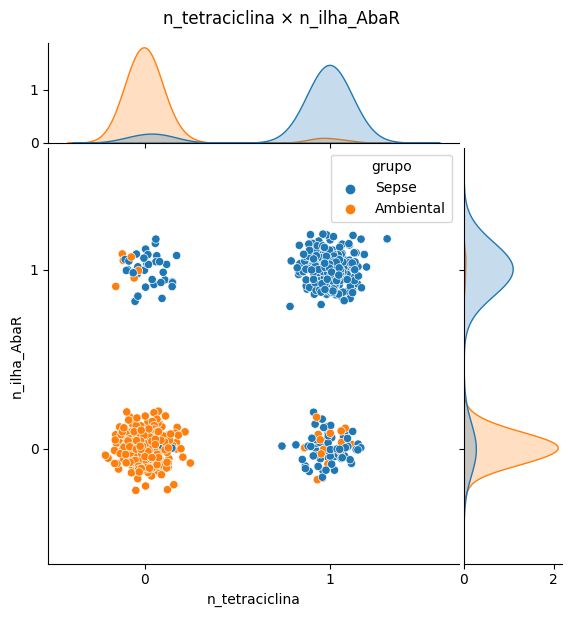

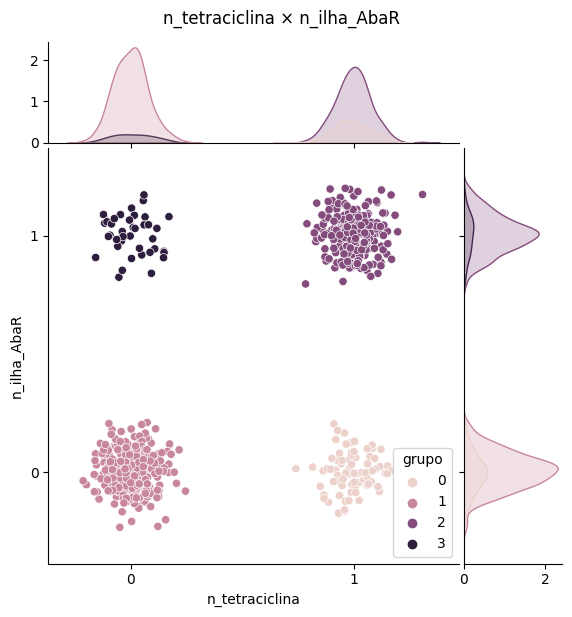

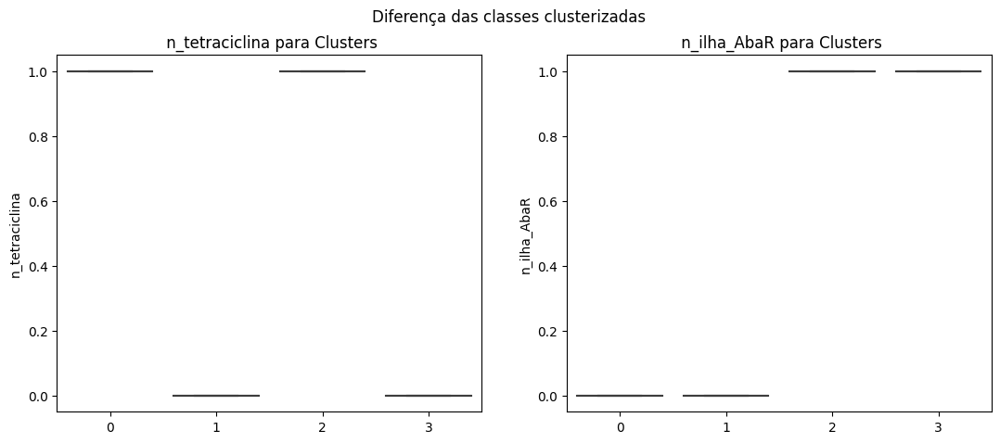

In [ ]:
#Analisando os clusters para variável n_tetraciclina e n_degradacao_aromaticos
i = bivariadas[1][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 6, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.9971

Silhouette Score -> 1.0
Calinski Harabasz Score -> 2.5837138410410775e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.55
Adjusted Mutual Info Score -> 0.548


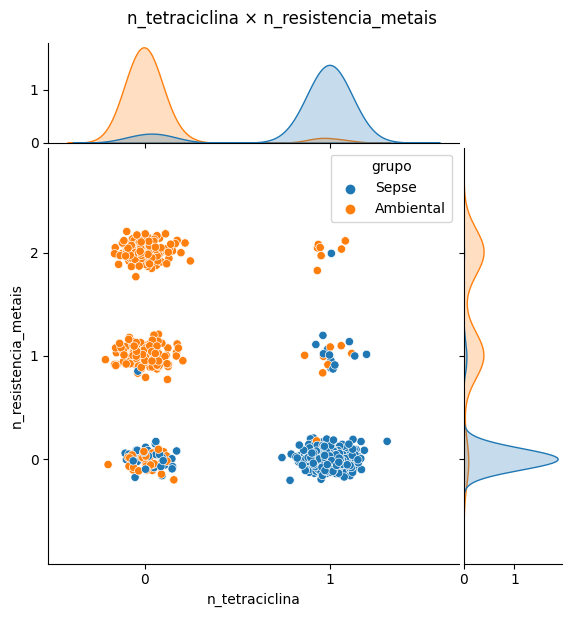

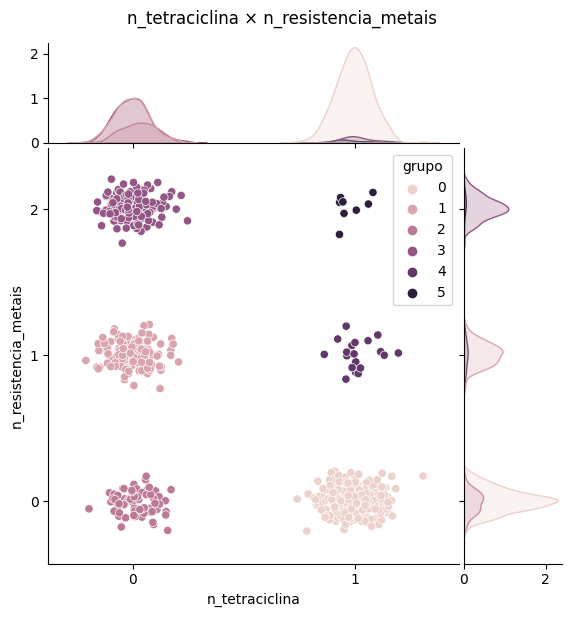

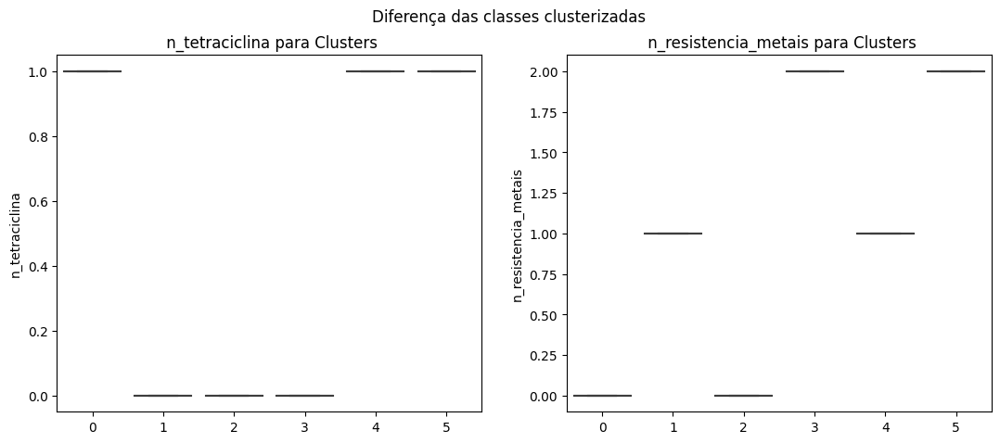

In [ ]:
#Analisando os clusters para variável n_polimixinas e n_degradacao_aromaticos
i = bivariadas[2][0]
j = bivariadas[2][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
data = {}
for i in range(100):
    cluster = Clustering(c1="n_tetraciclina", c2="n_polimixinas", df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,1.869472e+31,0.0,0.723,0.597
1,1.0,1.869472e+31,0.0,0.723,0.597
2,1.0,1.869472e+31,0.0,0.723,0.597
3,1.0,1.869472e+31,0.0,0.723,0.597
4,1.0,1.869472e+31,0.0,0.723,0.597


In [ ]:
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.0,1.000000e+02,100.0,100.000,1.000000e+02
mean,1.0,1.869472e+31,0.0,0.723,5.970000e-01
std,0.0,6.789432e+15,0.0,0.000,1.115816e-16
min,1.0,1.869472e+31,0.0,0.723,5.970000e-01
25%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
50%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
75%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
max,1.0,1.869472e+31,0.0,0.723,5.970000e-01


## Validação

In [ ]:
#Concatenando tabelas de validação
df_valid = pd.concat(
    [
        pd.read_csv("../tabelas/tabelas_finais/X_valid.csv"),
        pd.read_csv("../tabelas/tabelas_finais/y_valid.csv"),
    ],
    axis=1,
)

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
data = {}
for i in range(100):
    cluster = Clustering(
        c1='n_tetraciclina', c2='n_polimixinas', df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_kmeans = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_kmeans.head()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,6.161188e+31,0.0,0.577,0.451
1,1.0,6.161188e+31,0.0,0.577,0.451
2,1.0,6.161188e+31,0.0,0.577,0.451
3,1.0,6.161188e+31,0.0,0.577,0.451
4,1.0,6.161188e+31,0.0,0.577,0.451


In [ ]:
df_metricas_repeti_valid_kmeans.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.0,1.000000e+02,100.0,1.000000e+02,1.000000e+02
mean,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
std,0.0,2.715773e+16,0.0,1.115816e-16,5.579081e-17
min,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
25%,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
50%,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
75%,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
max,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01


/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 6.161187620311881e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.577
Adjusted Mutual Info Score -> 0.451


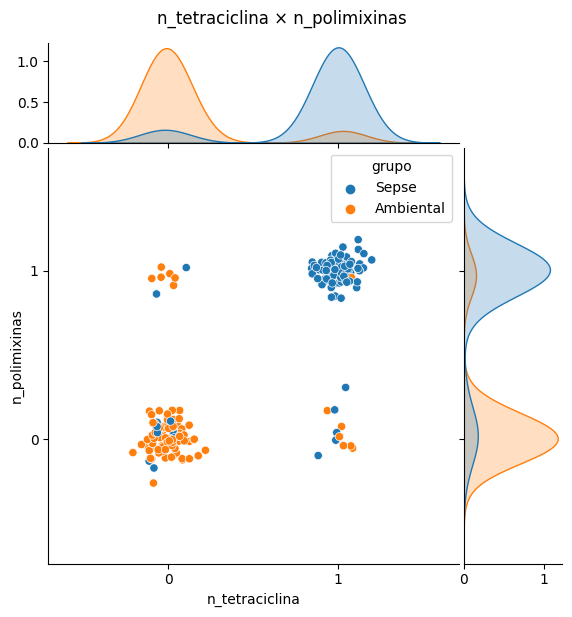

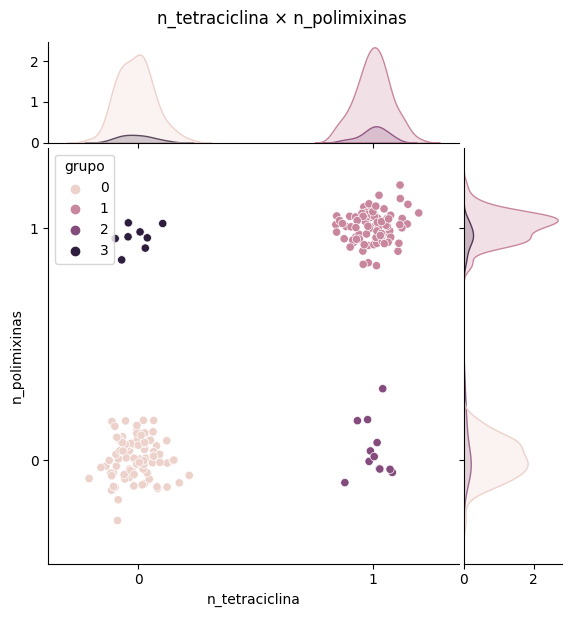

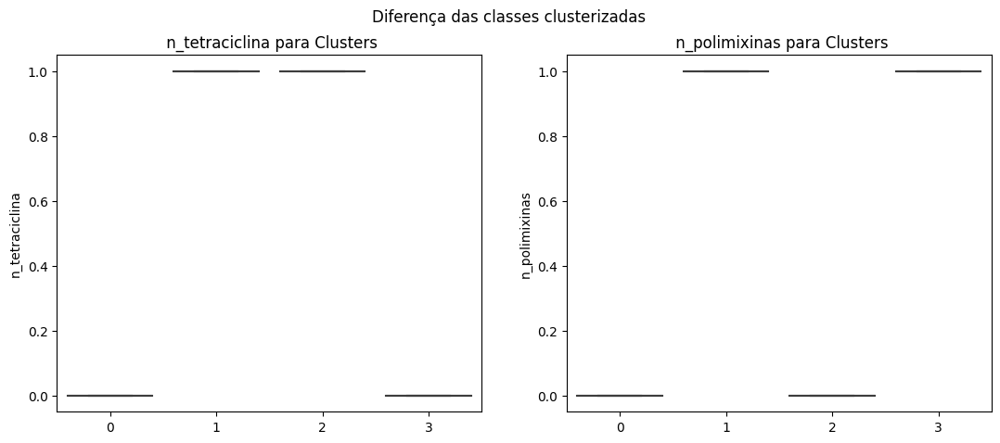

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
cluster = Clustering(c1='n_tetraciclina', c2='n_polimixinas', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (4) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 0.9950

Silhouette Score -> 1.0
Calinski Harabasz Score -> 4.95139627254021e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.636
Adjusted Mutual Info Score -> 0.576


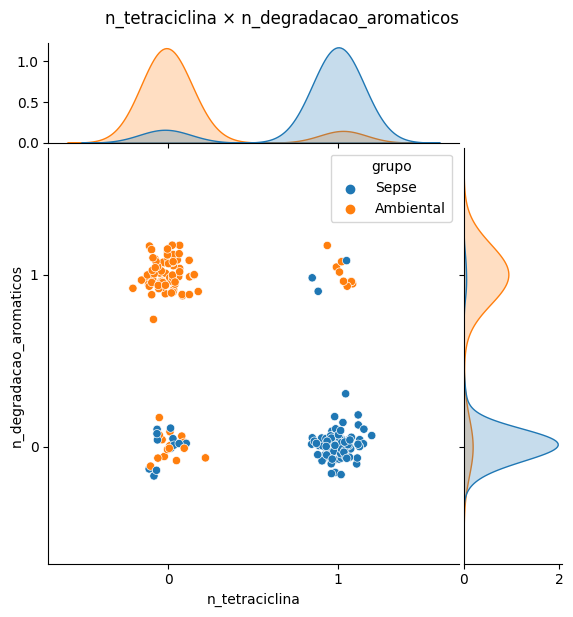

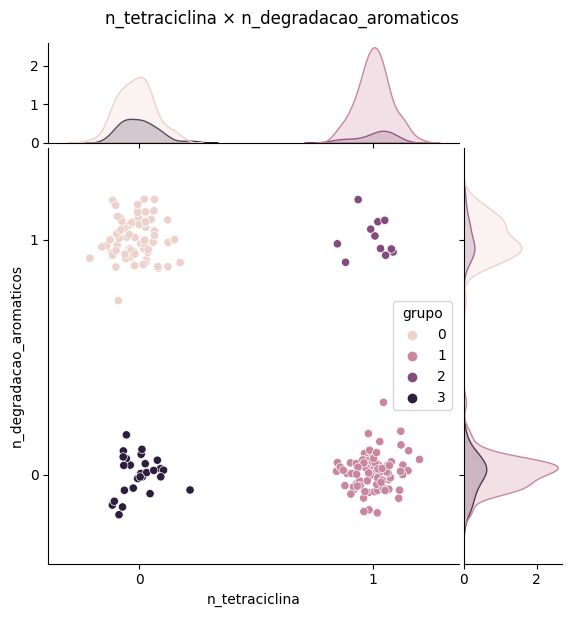

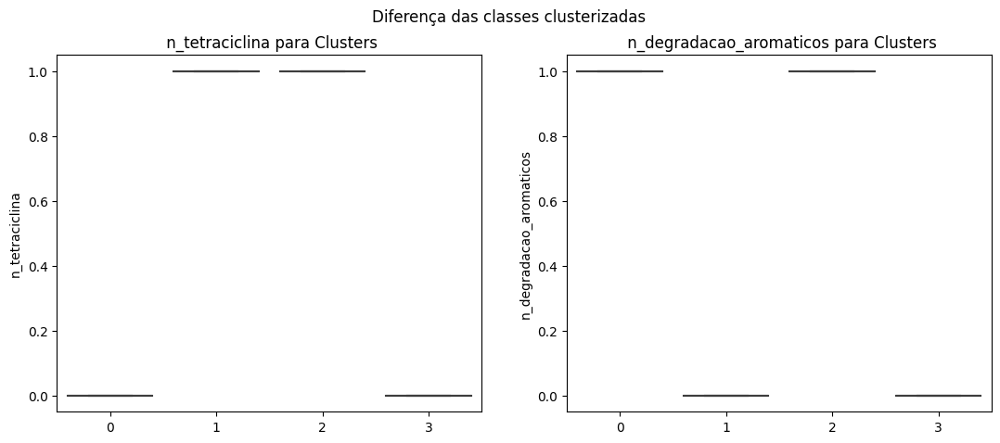

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_degradacao_aromaticos
cluster = Clustering(c1='n_tetraciclina', c2='n_degradacao_aromaticos', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (4). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/home/isabel.ribeiro/.conda/envs/ml_clusterizacao/lib/python3.10/site-packages/sklearn/base.py:1474: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_c

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'init': 'k-means++', 'n_init': 'auto'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 2.847303874275439e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.603
Adjusted Mutual Info Score -> 0.541


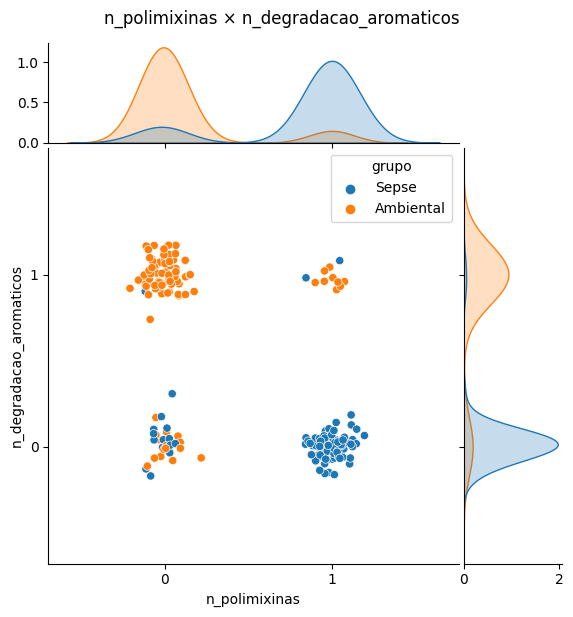

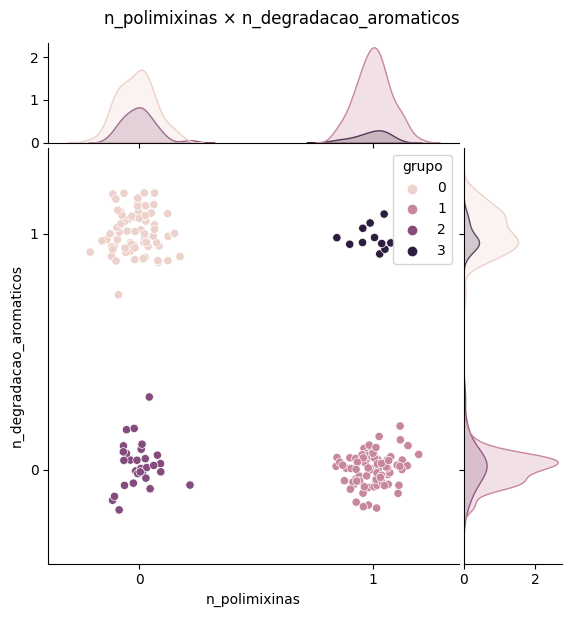

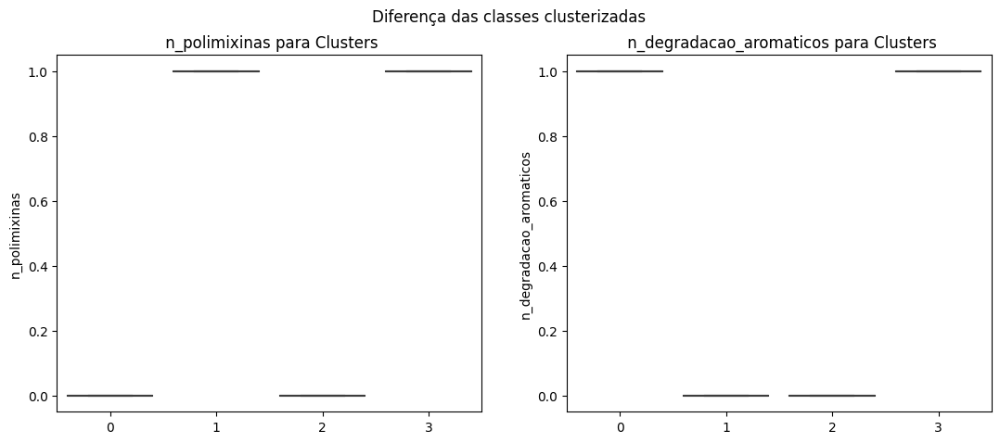

In [ ]:
#Repetindo as análises 100 vezes - n_polimixinas e n_degradacao_aromaticos
cluster = Clustering(c1='n_polimixinas', c2='n_degradacao_aromaticos', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

# DBSCAN

## Treino

In [ ]:
#Definindo um objeto com os dados de treino
nome_modelo = "dbscan"
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([0, 0, 0, 0, 1])

In [ ]:
#Obtendo as métricas de avaliação para todas as combinações
data = {}
for i in df_train.columns[:-2]:
    for j in df_train.columns[:-2]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
n_OXA_n_MBL,1.0,3.594766e+31,0.0,0.113,0.114
n_OXA_n_ISAba1,1.0,1.080668e+32,0.0,0.053,0.070
n_OXA_n_ESBL,1.0,5.067300e+31,0.0,0.136,0.236
n_OXA_n_aminoglicosideos,1.0,9.696349e+31,0.0,0.094,0.202
n_OXA_n_sulfa_trimetoprim,1.0,8.404415e+31,0.0,0.134,0.233


In [ ]:
#Selecionando as melhores combinações de variáveis
display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nsmallest(1))
display(df_metricas["Davies Bouldin"].nlargest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

n_OXA_n_MBL    1.0
Name: Silhouette, dtype: float64

n_virulencia_clinica_n_degradacao_aromaticos    7.672804e+30
Name: Calinski Harabasz, dtype: float64

n_OXA_n_MBL    0.0
Name: Davies Bouldin, dtype: float64

n_tetraciclina_n_polimixinas    0.723
Name: Adjusted Rand, dtype: float64

n_tetraciclina_n_ilha_AbaR    0.628
Name: Adjusted Mutual Info, dtype: float64

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.869472497498417e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.723
Adjusted Mutual Info Score -> 0.597


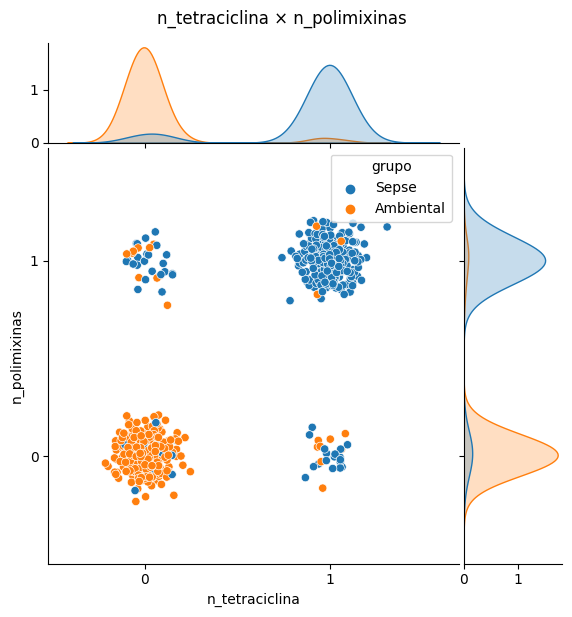

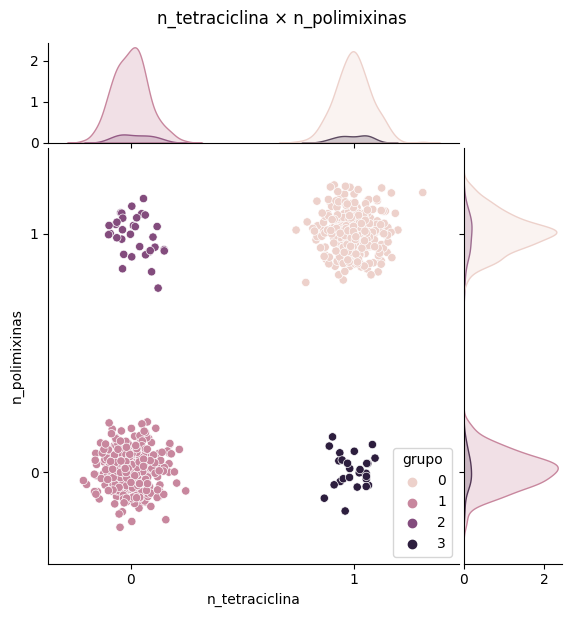

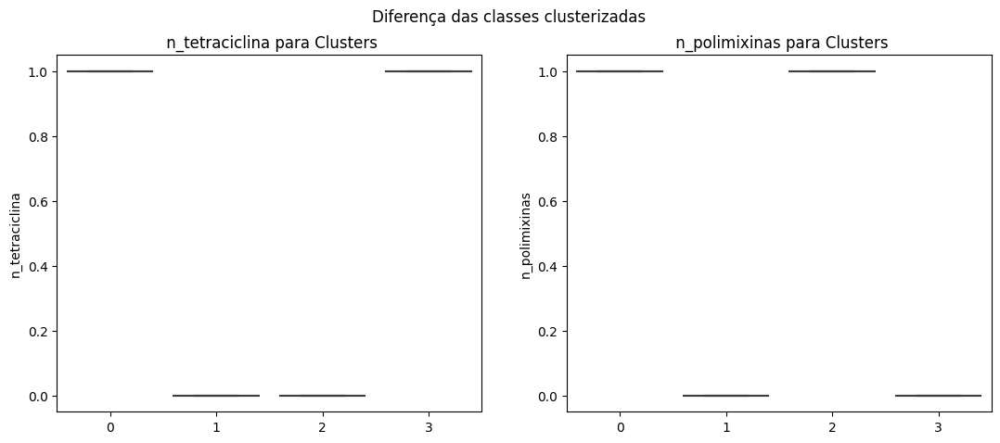

In [ ]:
#Avaliando entre n_tetraciclina e n_polimixinas
i = bivariadas[0][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.2031311635893638e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.683
Adjusted Mutual Info Score -> 0.628


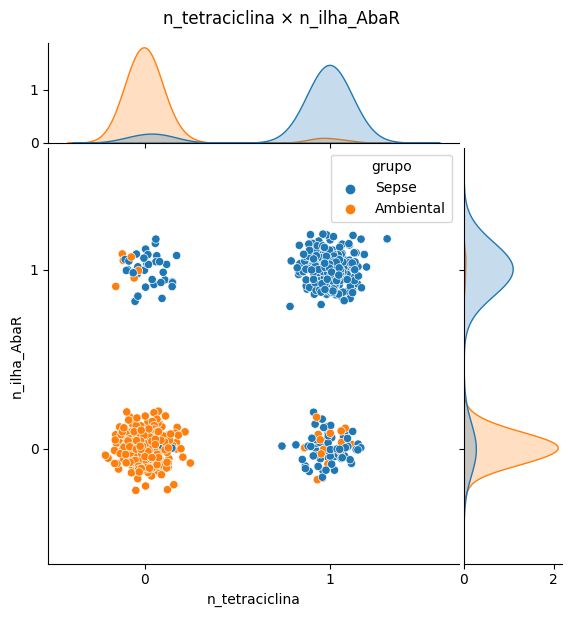

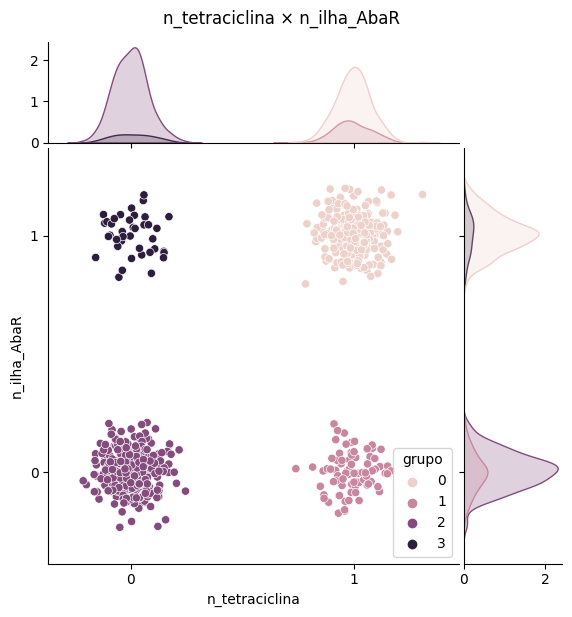

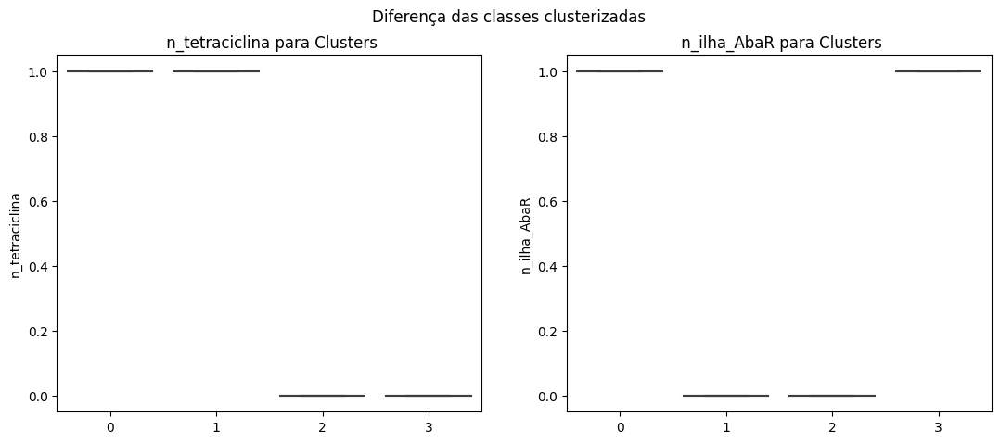

In [ ]:
#Analisando os clusters para variável n_tetraciclina e n_degradacao_aromaticos
i = bivariadas[1][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.9963

Silhouette Score -> 1.0
Calinski Harabasz Score -> 2.5837138410410775e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.55
Adjusted Mutual Info Score -> 0.548


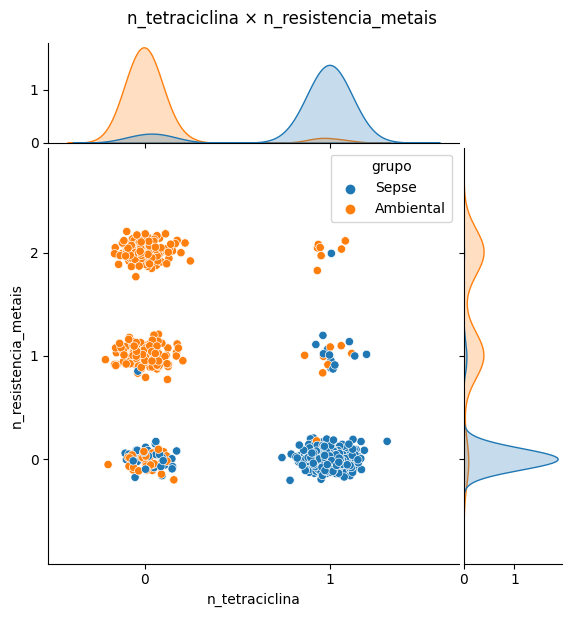

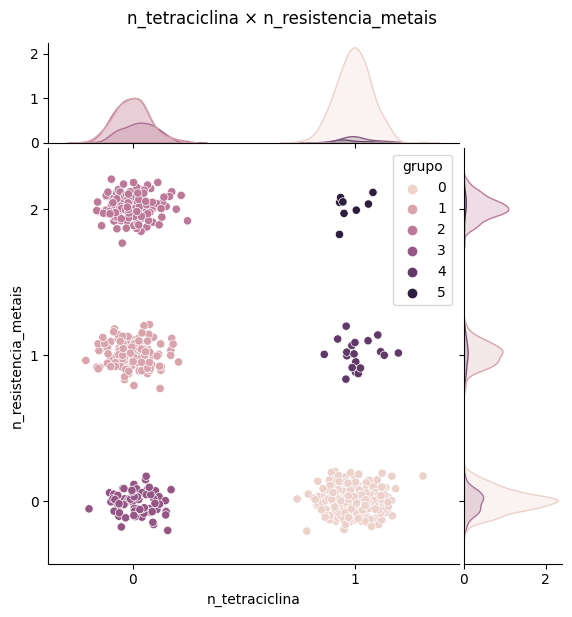

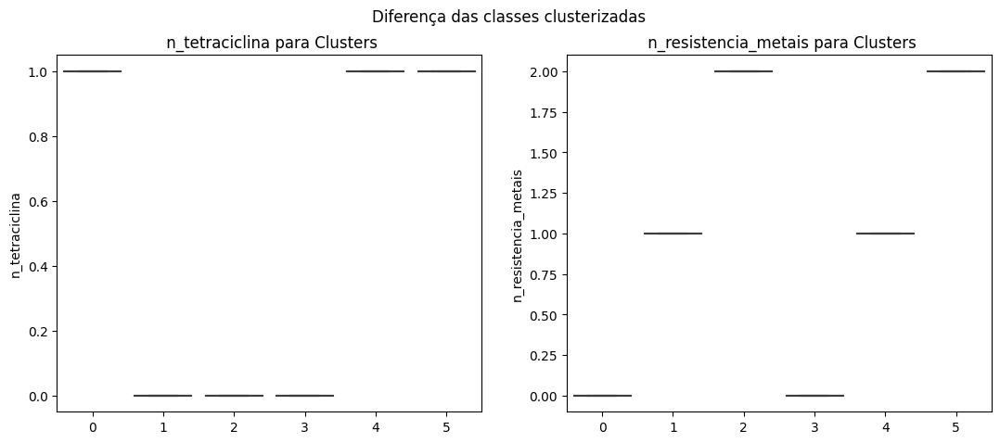

In [ ]:
#Analisando os clusters para variável n_polimixinas e n_degradacao_aromaticos
i = bivariadas[2][0]
j = bivariadas[2][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.3855698811692187e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.687
Adjusted Mutual Info Score -> 0.595


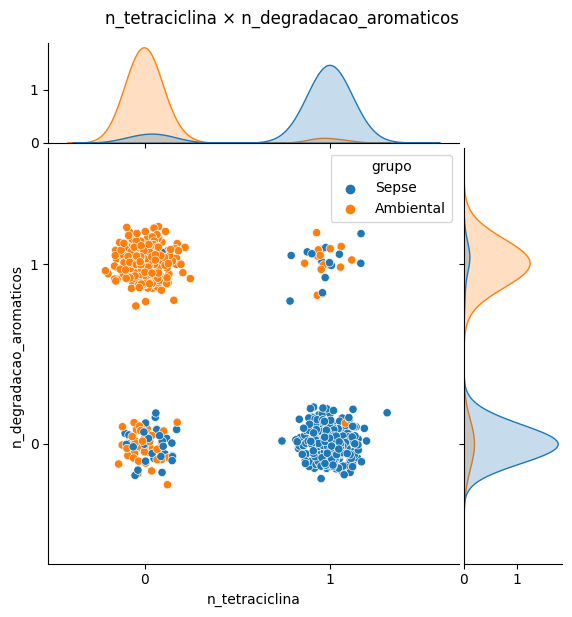

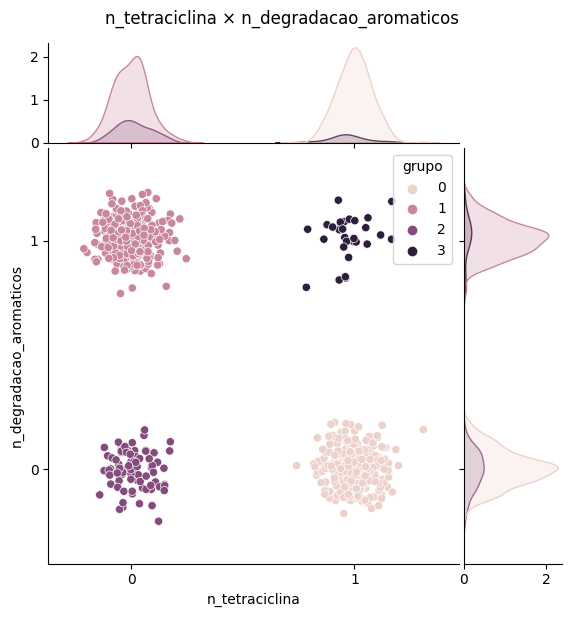

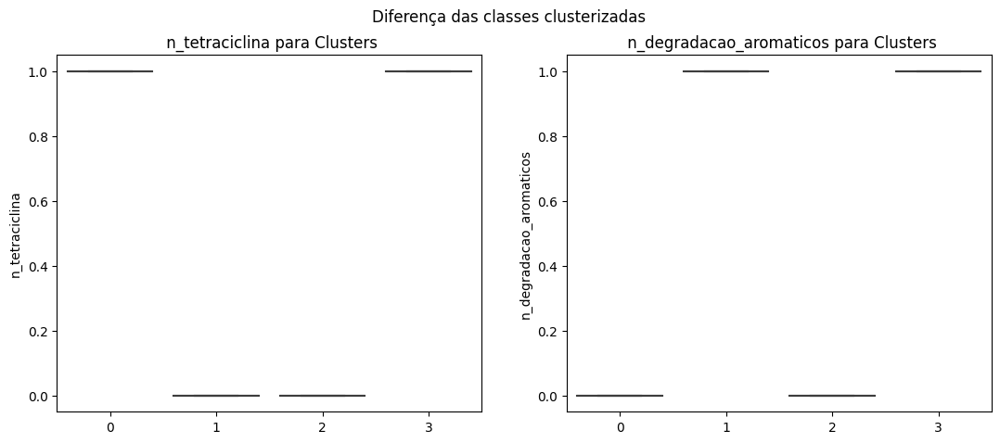

In [ ]:
#Analisando os clusters para variável n_virulencia_clinica e n_ilha_AbaR
i = bivariadas[3][0]
j = bivariadas[3][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
data = {}
for i in range(100):
    cluster = Clustering(c1="n_tetraciclina", c2="n_polimixinas", df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,1.869472e+31,0.0,0.723,0.597
1,1.0,1.869472e+31,0.0,0.723,0.597
2,1.0,1.869472e+31,0.0,0.723,0.597
3,1.0,1.869472e+31,0.0,0.723,0.597
4,1.0,1.869472e+31,0.0,0.723,0.597


In [ ]:
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.0,1.000000e+02,100.0,100.000,1.000000e+02
mean,1.0,1.869472e+31,0.0,0.723,5.970000e-01
std,0.0,6.789432e+15,0.0,0.000,1.115816e-16
min,1.0,1.869472e+31,0.0,0.723,5.970000e-01
25%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
50%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
75%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
max,1.0,1.869472e+31,0.0,0.723,5.970000e-01


## Validação

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
data = {}
for i in range(100):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_dbscan = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_dbscan.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,6.161188e+31,0.0,0.577,0.451
1,1.0,6.161188e+31,0.0,0.577,0.451
2,1.0,6.161188e+31,0.0,0.577,0.451
3,1.0,6.161188e+31,0.0,0.577,0.451
4,1.0,6.161188e+31,0.0,0.577,0.451


In [ ]:
df_metricas_repeti_valid_dbscan.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.0,1.000000e+02,100.0,1.000000e+02,1.000000e+02
mean,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
std,0.0,2.715773e+16,0.0,1.115816e-16,5.579081e-17
min,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
25%,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
50%,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
75%,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01
max,1.0,6.161188e+31,0.0,5.770000e-01,4.510000e-01


=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.9811

Silhouette Score -> 1.0
Calinski Harabasz Score -> 6.161187620311881e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.577
Adjusted Mutual Info Score -> 0.451


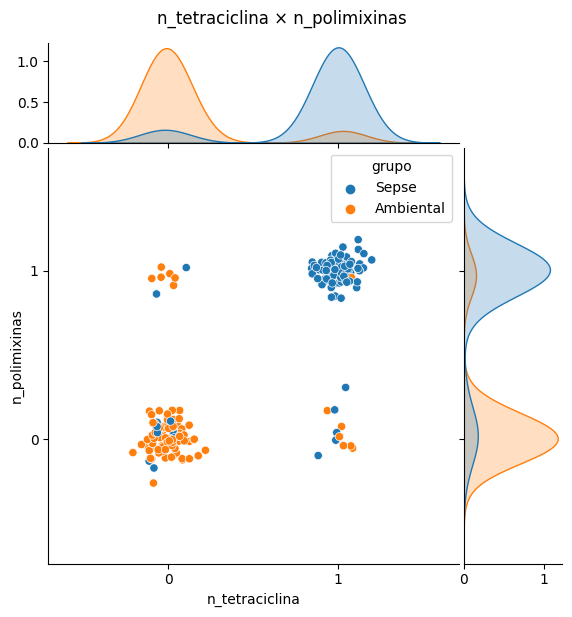

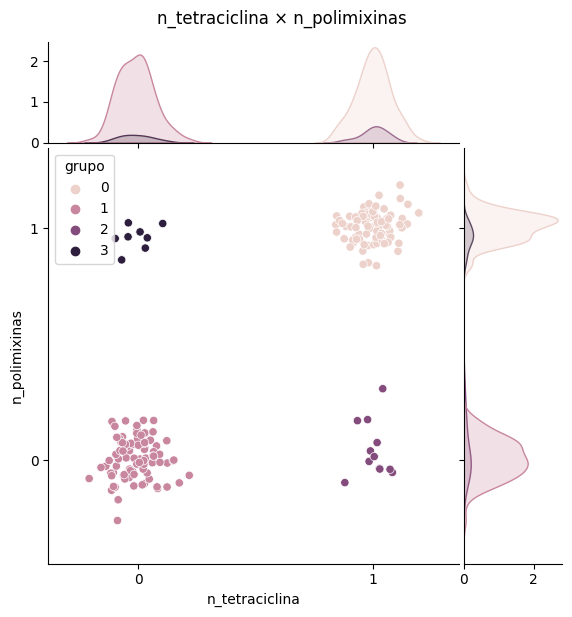

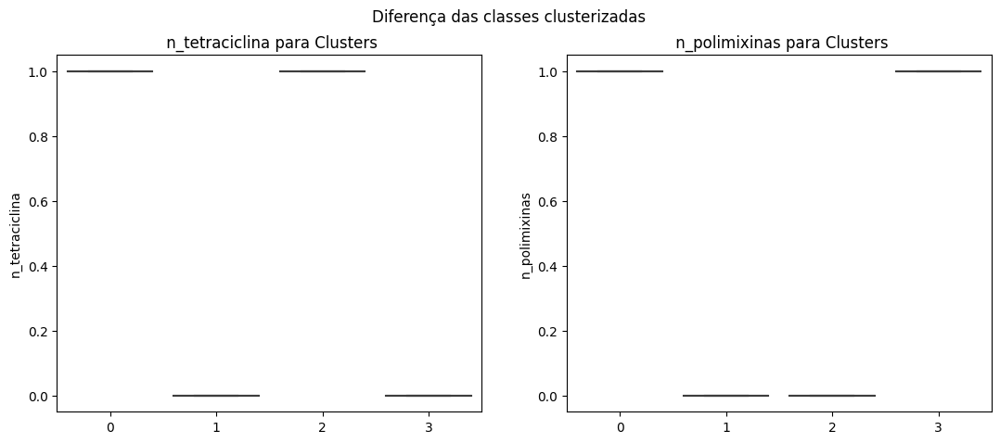

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
cluster = Clustering(c1='n_tetraciclina', c2='n_polimixinas', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 0.9950

Silhouette Score -> 1.0
Calinski Harabasz Score -> 4.95139627254021e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.636
Adjusted Mutual Info Score -> 0.576


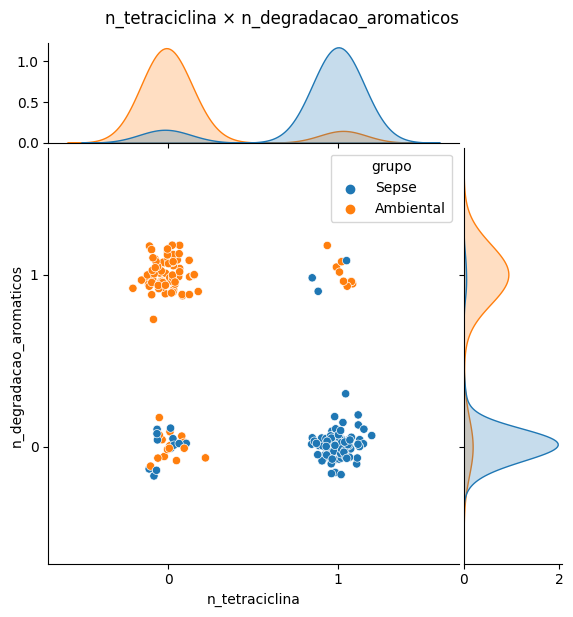

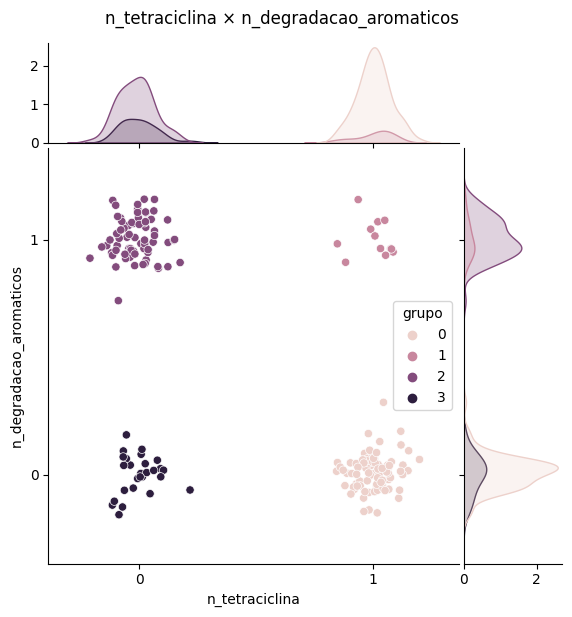

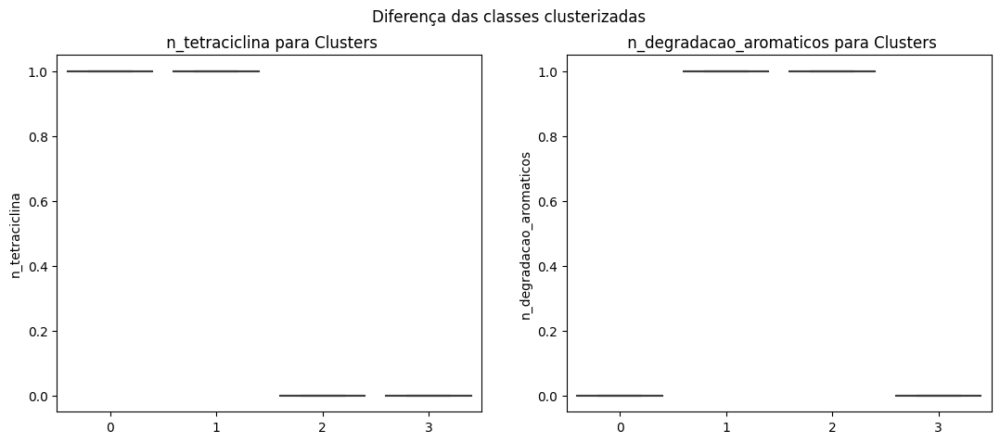

In [ ]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_degradacao_aromaticos
cluster = Clustering(c1='n_tetraciclina', c2='n_degradacao_aromaticos', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'eps': 0.1, 'min_samples': 3, 'metric': 'euclidean'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 2.847303874275439e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.603
Adjusted Mutual Info Score -> 0.541


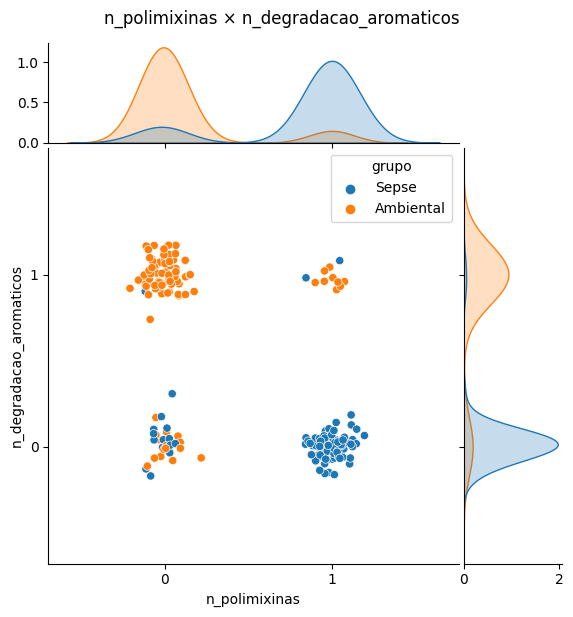

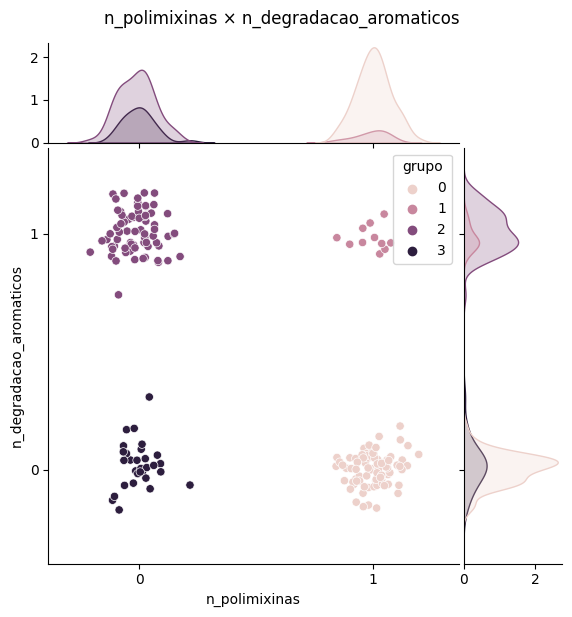

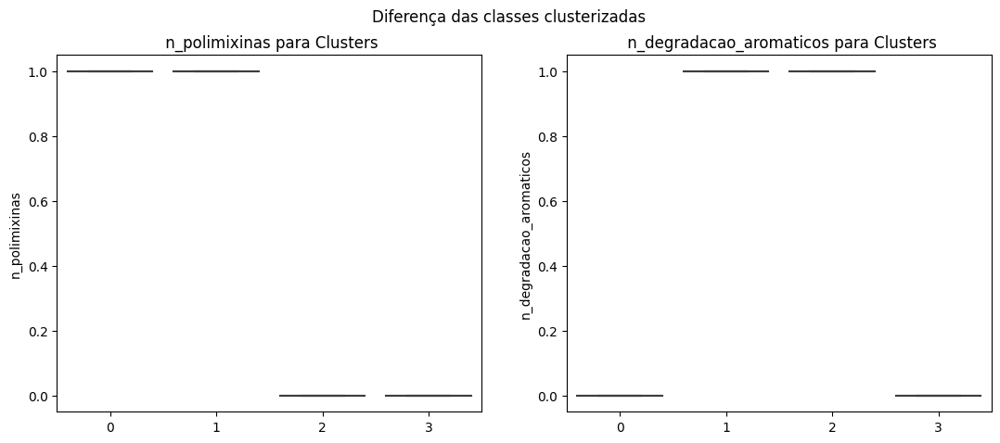

In [71]:
#Repetindo as análises 100 vezes - n_polimixinas e n_degradacao_aromaticos
cluster = Clustering(c1='n_polimixinas', c2='n_degradacao_aromaticos', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

# Agrupamento Hierarquico

## Treino

In [73]:
#Testando modelos de clusterização por agrupamento hierarquico
param_combinations = [
    {"n_clusters": k, "linkage": "ward", "metric": "euclidean"} for k in [2, 3, 4, 5, 6]
] + [
    {"n_clusters": k, "linkage": linkage, "metric": metric}
    for k in [2, 3, 4, 5, 6]
    for linkage in ["complete", "average", "single"]
    for metric in ["euclidean", "manhattan", "cosine"]
]
param_combinations

[{'n_clusters': 2, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 3, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 4, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 5, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 6, 'linkage': 'ward', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'complete', 'metric': 'cosine'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'average', 'metric': 'cosine'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'euclidean'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'manhattan'},
 {'n_clusters': 2, 'linkage': 'single', 'metric': 'cosine'},
 {'n_clusters': 3, 'linkage': 'complete', 'metric': 'euclidean'},
 {'n_clusters': 3, 'linkage': 'complete', 'metri

In [74]:
#Treino no modelo agglomerative
nome_modelo = "agglomerative"
cluster = Clustering(
    c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_train, modelo=nome_modelo
)
cluster.cross_validation(print_metricas=False)[0][:5]

array([1, 1, 1, 1, 3])

In [75]:
# Obtendo as métricas de avaliação de clustering para todas as combinações
for i in df_train.columns[:-2]:
    for j in df_train.columns[:-2]:
        if i != j:
            cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
            _, metricas = cluster.cross_validation(print_metricas=False)
            data[i + "_" + j] = metricas
df_metricas = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,6.161188e+31,0.0,0.577,0.451
1,1.0,6.161188e+31,0.0,0.577,0.451
2,1.0,6.161188e+31,0.0,0.577,0.451
3,1.0,6.161188e+31,0.0,0.577,0.451
4,1.0,6.161188e+31,0.0,0.577,0.451


In [76]:
# Selecionando as melhores combinações de variáveis
display(df_metricas["Silhouette"].nlargest(1))
display(df_metricas["Calinski Harabasz"].nsmallest(1))
display(df_metricas["Davies Bouldin"].nlargest(1))
display(df_metricas["Adjusted Rand"].nlargest(1))
display(df_metricas["Adjusted Mutual Info"].nlargest(1))

0    1.0
Name: Silhouette, dtype: float64

n_OXA_n_ESBL    1193.694
Name: Calinski Harabasz, dtype: float64

n_ISAba1_n_aminoglicosideos    0.71
Name: Davies Bouldin, dtype: float64

n_tetraciclina_n_polimixinas    0.723
Name: Adjusted Rand, dtype: float64

n_tetraciclina_n_ilha_AbaR    0.628
Name: Adjusted Mutual Info, dtype: float64

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.869472497498417e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.723
Adjusted Mutual Info Score -> 0.597


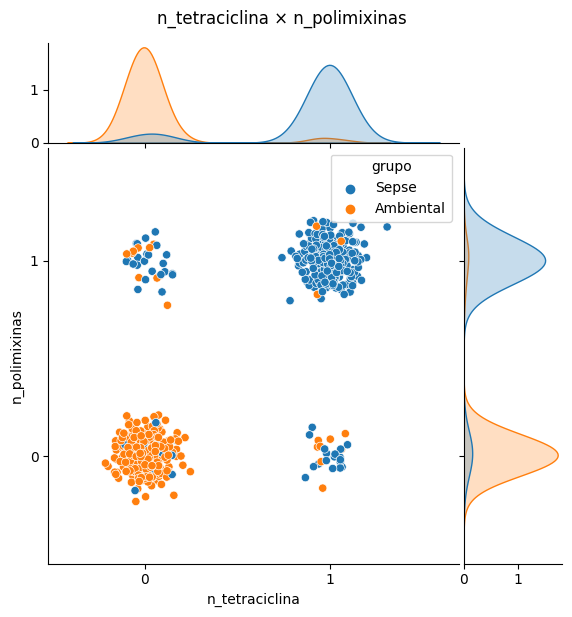

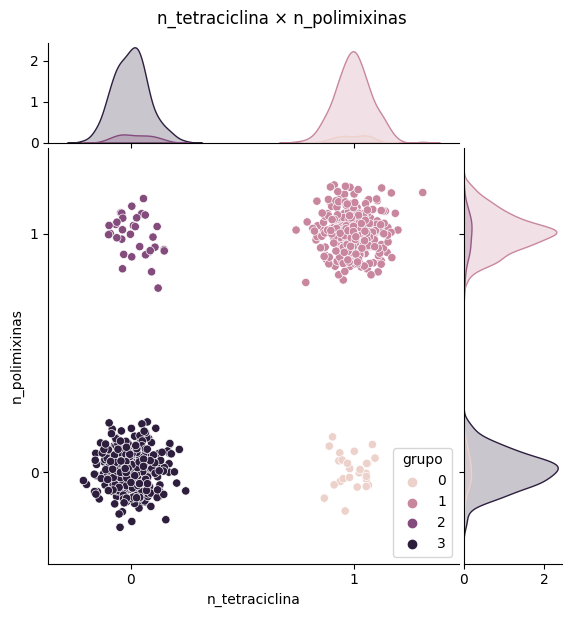

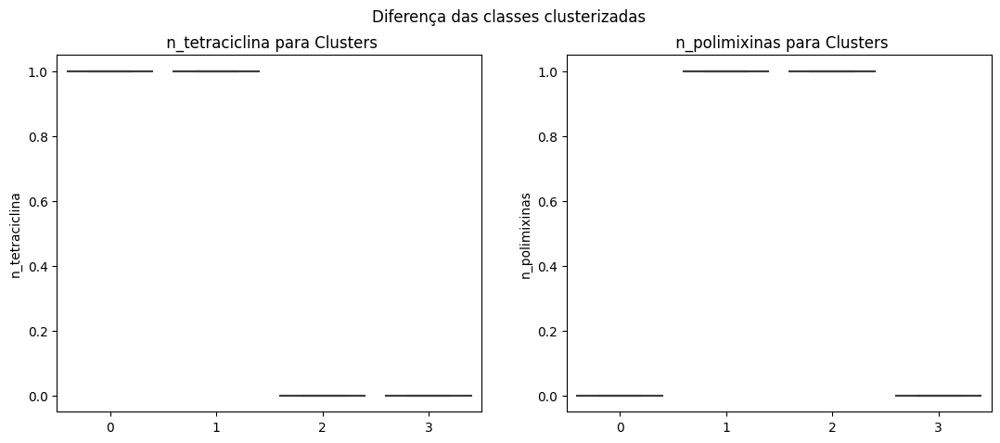

In [77]:
#Avaliando entre n_tetraciclina e n_polimixinas
i = bivariadas[0][0]
j = bivariadas[0][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.2031311635893638e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.683
Adjusted Mutual Info Score -> 0.628


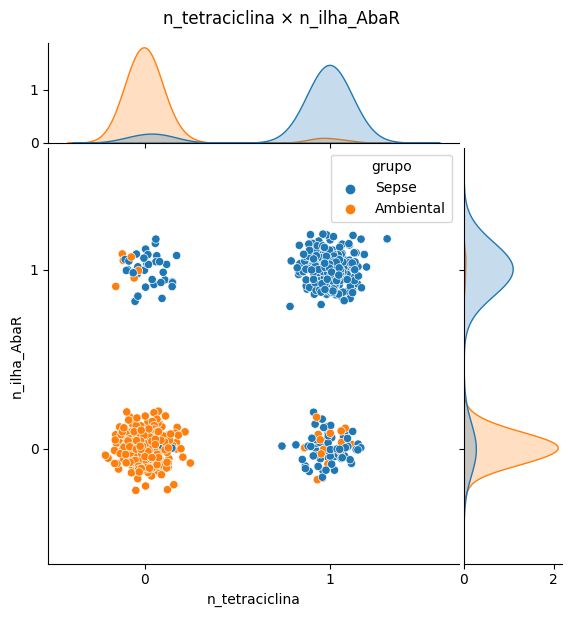

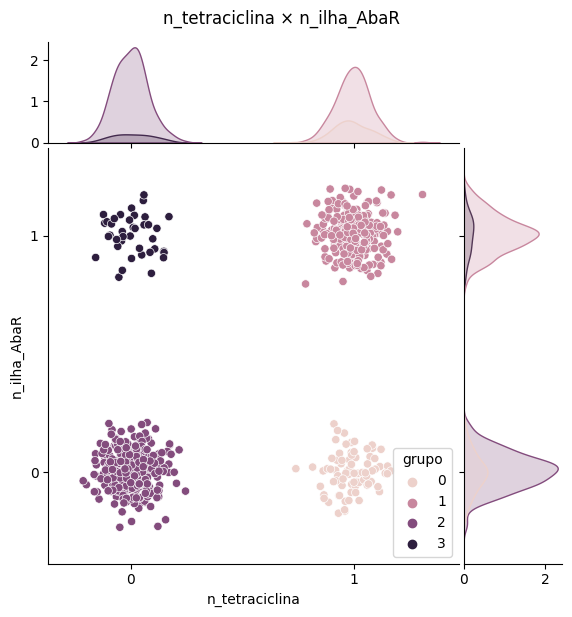

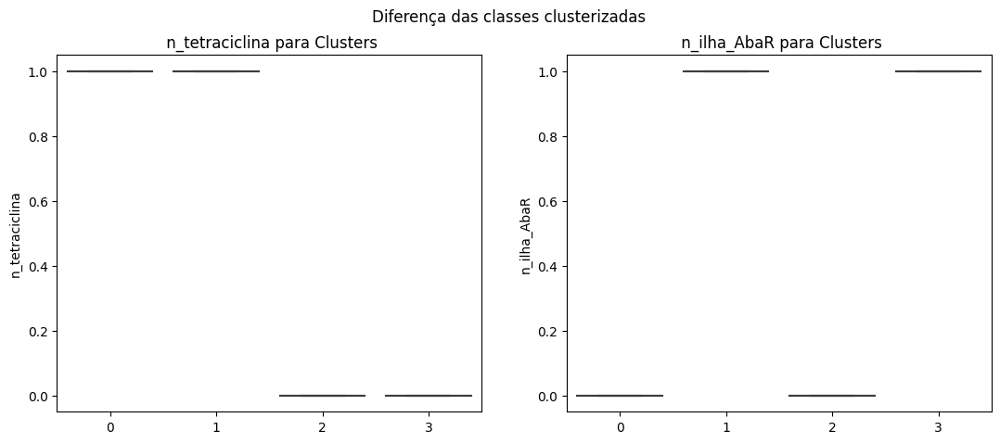

In [78]:
#Analisando os clusters para variável n_tetraciclina e n_degradacao_aromaticos
i = bivariadas[1][0]
j = bivariadas[1][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 5, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.9869

Silhouette Score -> 0.987
Calinski Harabasz Score -> 28363.864
Davies Bouldin Score -> 0.266
Adjusted Rand Score -> 0.55
Adjusted Mutual Info Score -> 0.55


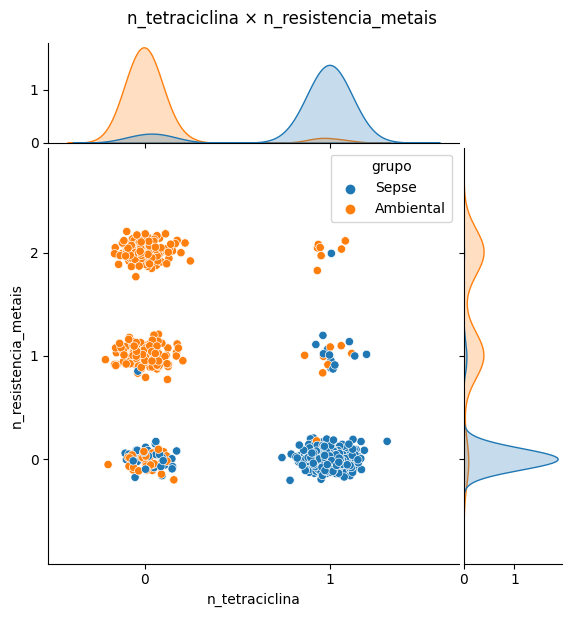

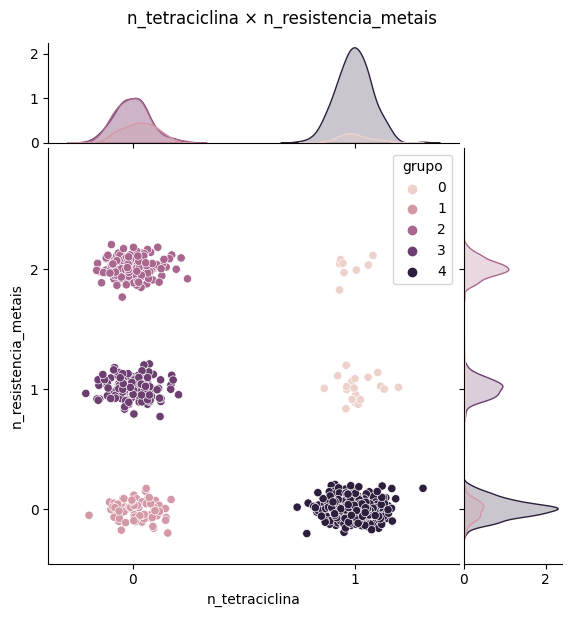

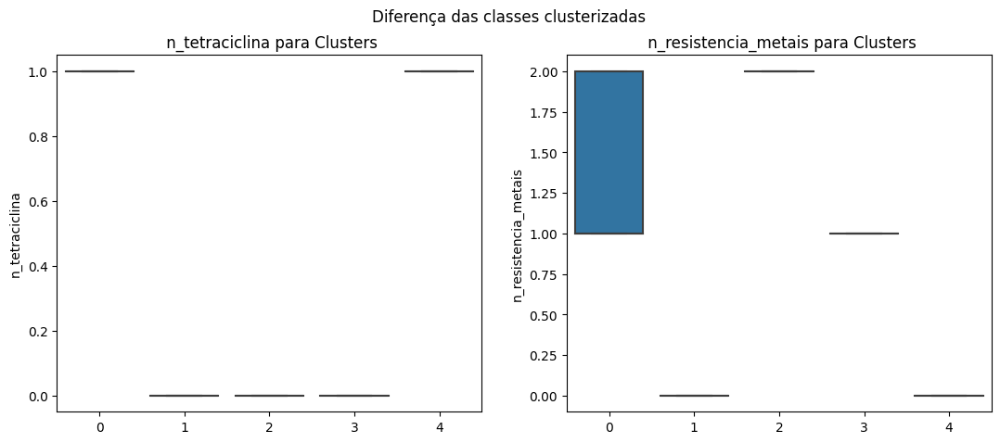

In [79]:
#Analisando os clusters para variável n_polimixinas e n_degradacao_aromaticos
i = bivariadas[2][0]
j = bivariadas[2][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 1.0000

Silhouette Score -> 1.0
Calinski Harabasz Score -> 1.3855698811692187e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.687
Adjusted Mutual Info Score -> 0.595


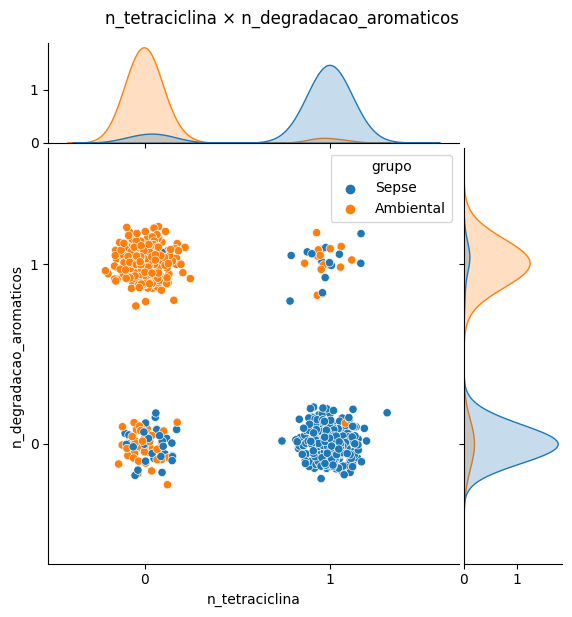

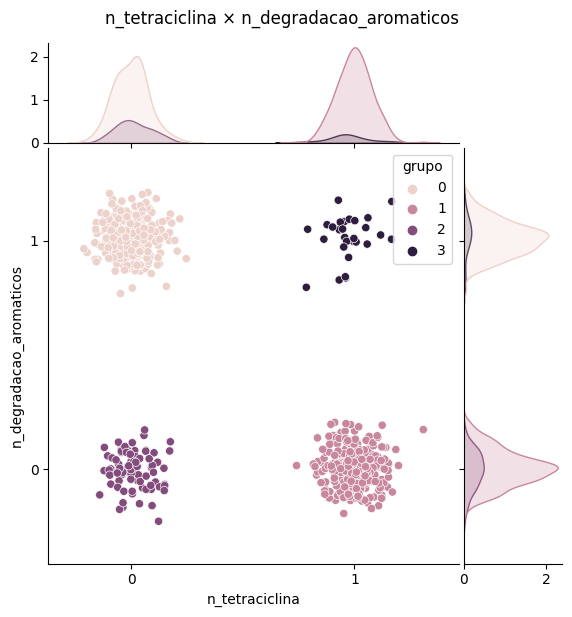

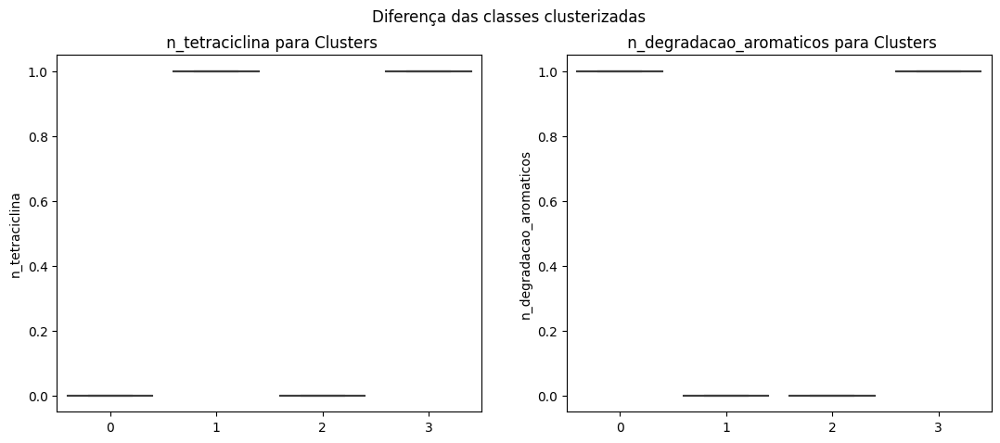

In [80]:
#Analisando os clusters para variável n_virulencia_clinica e n_ilha_AbaR
i = bivariadas[3][0]
j = bivariadas[3][1]
cluster = Clustering(c1=i, c2=j, df=df_train, modelo=nome_modelo)
cluster.cross_validation()

In [81]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
data = {}
for i in range(100):
    cluster = Clustering(c1="n_polimixinas", c2="n_tetraciclina", df=df_train, modelo=nome_modelo)
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,1.0,1.869472e+31,0.0,0.723,0.597
1,1.0,1.869472e+31,0.0,0.723,0.597
2,1.0,1.869472e+31,0.0,0.723,0.597
3,1.0,1.869472e+31,0.0,0.723,0.597
4,1.0,1.869472e+31,0.0,0.723,0.597


In [82]:
df_metricas_repeti.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.0,1.000000e+02,100.0,100.000,1.000000e+02
mean,1.0,1.869472e+31,0.0,0.723,5.970000e-01
std,0.0,6.789432e+15,0.0,0.000,1.115816e-16
min,1.0,1.869472e+31,0.0,0.723,5.970000e-01
25%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
50%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
75%,1.0,1.869472e+31,0.0,0.723,5.970000e-01
max,1.0,1.869472e+31,0.0,0.723,5.970000e-01


## Validação

In [83]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
data = {}
for i in range(100):
    cluster = Clustering(
        c1=bivariadas[0][0], c2=bivariadas[0][1], df=df_valid, modelo=nome_modelo
    )
    _, metricas = cluster.cross_validation(print_metricas=False)
    data[i] = metricas

df_metricas_repeti_valid_agg = pd.DataFrame(data).T.rename(
    columns={
        0: "Silhouette",
        1: "Calinski Harabasz",
        2: "Davies Bouldin",
        3: "Adjusted Rand",
        4: "Adjusted Mutual Info",
    }
)
df_metricas_repeti_valid_agg.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
0,0.926,1244.682,0.139,0.545,0.42
1,0.926,1244.682,0.139,0.545,0.42
2,0.926,1244.682,0.139,0.545,0.42
3,0.926,1244.682,0.139,0.545,0.42
4,0.926,1244.682,0.139,0.545,0.42


In [84]:
df_metricas_repeti_valid_agg.describe()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info
count,100.000,1.000000e+02,1.000000e+02,100.000,1.000000e+02
mean,0.926,1.244682e+03,1.390000e-01,0.545,4.200000e-01
std,0.000,2.285191e-13,2.789540e-17,0.000,1.115816e-16
min,0.926,1.244682e+03,1.390000e-01,0.545,4.200000e-01
25%,0.926,1.244682e+03,1.390000e-01,0.545,4.200000e-01
50%,0.926,1.244682e+03,1.390000e-01,0.545,4.200000e-01
75%,0.926,1.244682e+03,1.390000e-01,0.545,4.200000e-01
max,0.926,1.244682e+03,1.390000e-01,0.545,4.200000e-01


=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 3, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.9543

Silhouette Score -> 0.926
Calinski Harabasz Score -> 1244.682
Davies Bouldin Score -> 0.139
Adjusted Rand Score -> 0.545
Adjusted Mutual Info Score -> 0.42


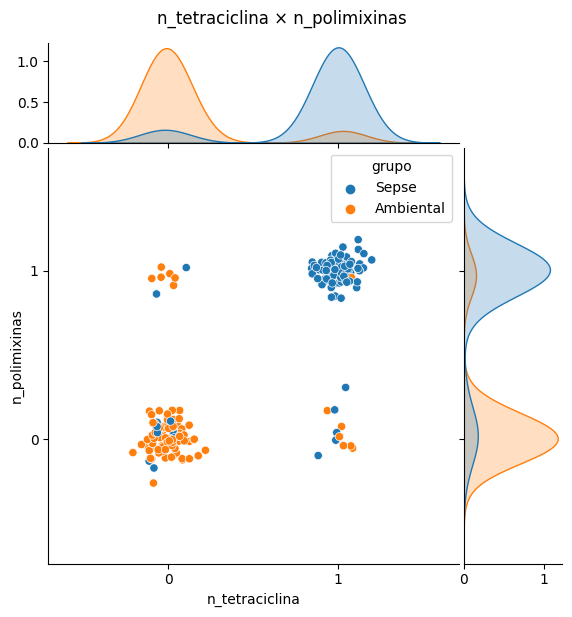

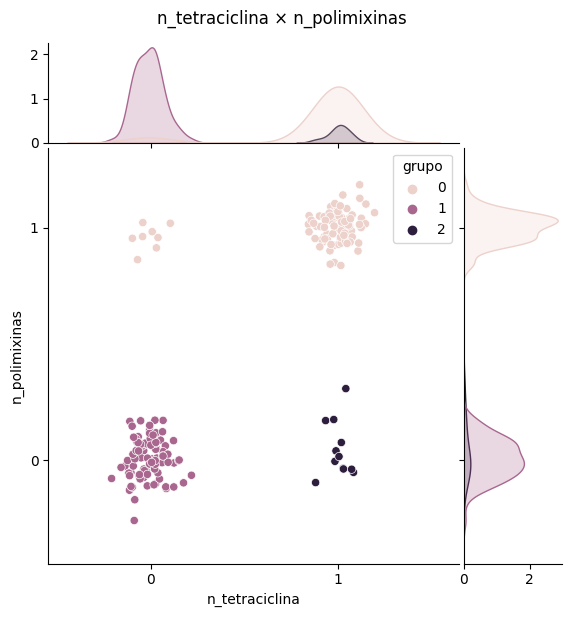

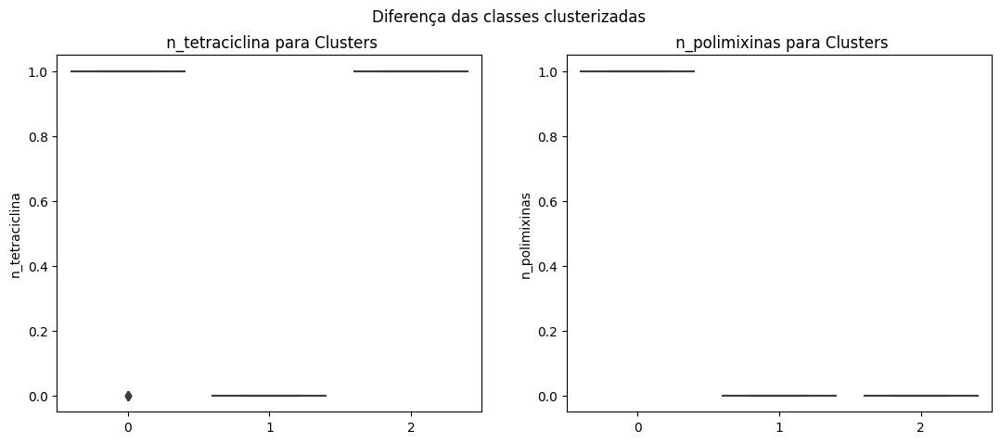

In [85]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_polimixinas
cluster = Clustering(c1='n_tetraciclina', c2='n_polimixinas', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'metric': 'euclidean', 'linkage': 'ward'}
Silhouette Score Médio (CV): 0.9950

Silhouette Score -> 1.0
Calinski Harabasz Score -> 4.95139627254021e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.636
Adjusted Mutual Info Score -> 0.576


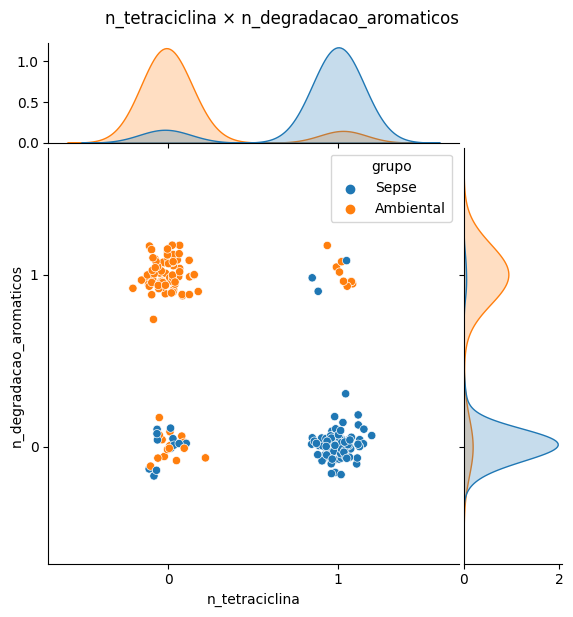

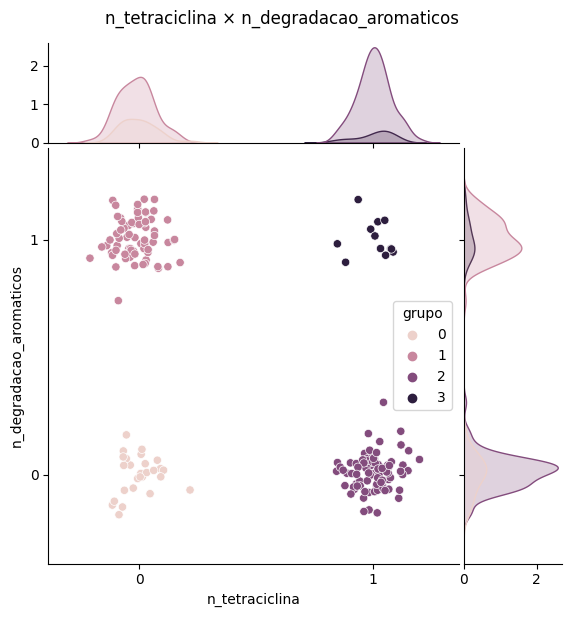

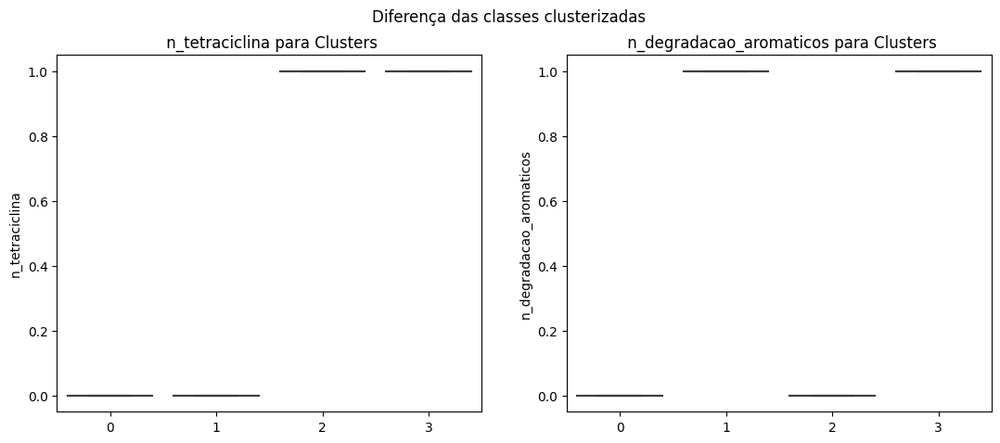

In [86]:
#Repetindo as análises 100 vezes - n_tetraciclina e n_degradacao_aromaticos
cluster = Clustering(c1='n_tetraciclina', c2='n_degradacao_aromaticos', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

=== MELHOR CONFIGURAÇÃO ENCONTRADA VIA cross_val_score ===
Parâmetros: {'n_clusters': 4, 'metric': 'euclidean', 'linkage': 'single'}
Silhouette Score Médio (CV): 0.9200

Silhouette Score -> 1.0
Calinski Harabasz Score -> 2.847303874275439e+31
Davies Bouldin Score -> 0.0
Adjusted Rand Score -> 0.603
Adjusted Mutual Info Score -> 0.541


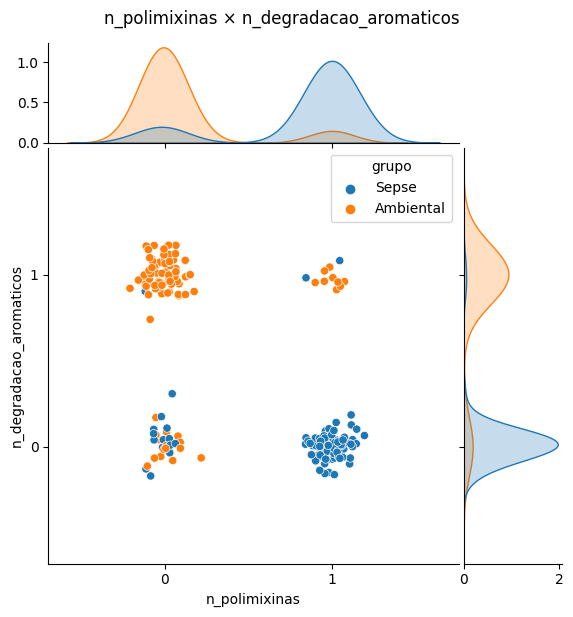

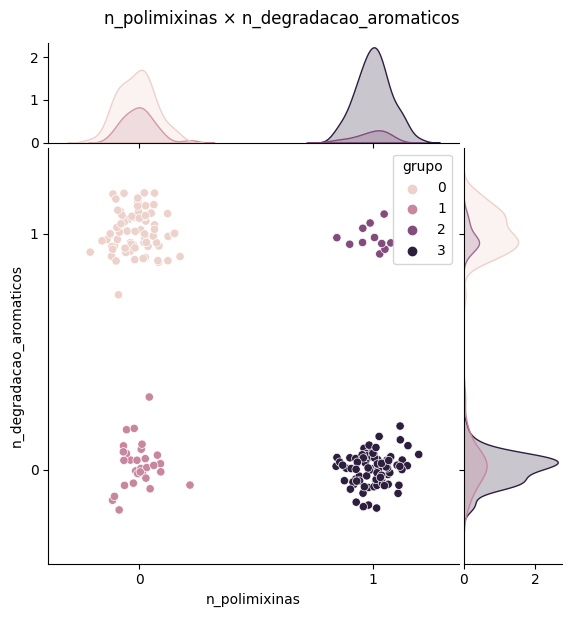

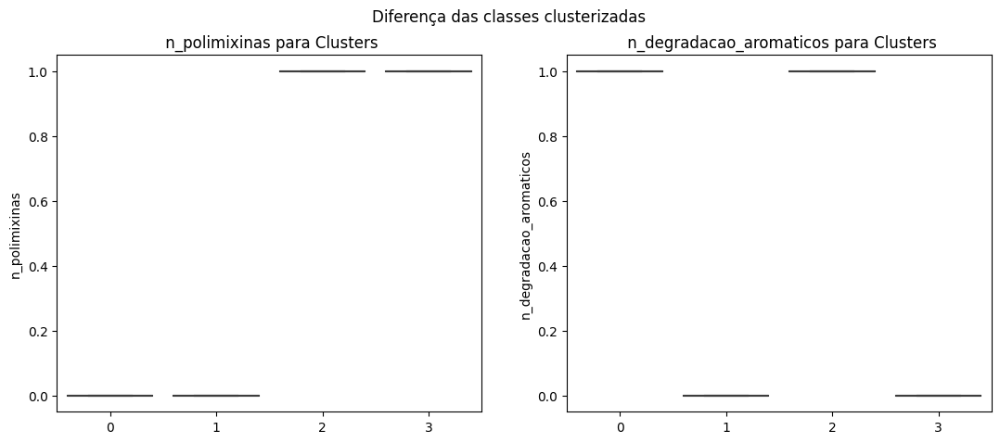

In [87]:
#Repetindo as análises 100 vezes - n_polimixinas e n_degradacao_aromaticos
cluster = Clustering(c1='n_polimixinas', c2='n_degradacao_aromaticos', 
                     df=df_valid, modelo=nome_modelo)
cluster.cross_validation()

## Análise de métricas de validação

In [89]:
# Salvando os dataframes de métricas de avaliação

# K-means
local = "./modelo_clus/df_metricas_valid_kmeans"
dump(df_metricas_repeti_valid_kmeans, local)
df_metricas_repeti_valid_kmeans = load(local)
df_metricas_repeti_valid_kmeans["algoritmo"] = "kmeans"
print("K-means")
display(df_metricas_repeti_valid_kmeans.head())

# DBSCAN
local = "./modelo_clus/df_metricas_valid_dbscan"
dump(df_metricas_repeti_valid_dbscan, local)
df_metricas_repeti_valid_dbscan = load(local)
df_metricas_repeti_valid_dbscan["algoritmo"] = "dbscan"
print("DBSCAN")
display(df_metricas_repeti_valid_dbscan.head())

# Agrupamento Hierárquico (Agglomerative)
local = "./modelo_clus/df_metricas_valid_agg"
dump(df_metricas_repeti_valid_agg, local)
df_metricas_repeti_valid_agg = load(local)
df_metricas_repeti_valid_agg["algoritmo"] = "agg"
print("Agglomerative")
display(df_metricas_repeti_valid_agg.head())

K-means


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
1,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
2,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
3,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
4,1.0,6.161188e+31,0.0,0.577,0.451,kmeans


DBSCAN


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,1.0,6.161188e+31,0.0,0.577,0.451,dbscan
1,1.0,6.161188e+31,0.0,0.577,0.451,dbscan
2,1.0,6.161188e+31,0.0,0.577,0.451,dbscan
3,1.0,6.161188e+31,0.0,0.577,0.451,dbscan
4,1.0,6.161188e+31,0.0,0.577,0.451,dbscan


Agglomerative


,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,0.926,1244.682,0.139,0.545,0.42,agg
1,0.926,1244.682,0.139,0.545,0.42,agg
2,0.926,1244.682,0.139,0.545,0.42,agg
3,0.926,1244.682,0.139,0.545,0.42,agg
4,0.926,1244.682,0.139,0.545,0.42,agg


In [97]:
# Agrupando os resultados das métricas de avaliação
df_metricas = pd.concat(
    [
        df_metricas_repeti_valid_kmeans,
        df_metricas_repeti_valid_dbscan,
        df_metricas_repeti_valid_agg,
    ],
    axis=0,
)
df_metricas.head()

,Silhouette,Calinski Harabasz,Davies Bouldin,Adjusted Rand,Adjusted Mutual Info,algoritmo
0,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
1,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
2,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
3,1.0,6.161188e+31,0.0,0.577,0.451,kmeans
4,1.0,6.161188e+31,0.0,0.577,0.451,kmeans


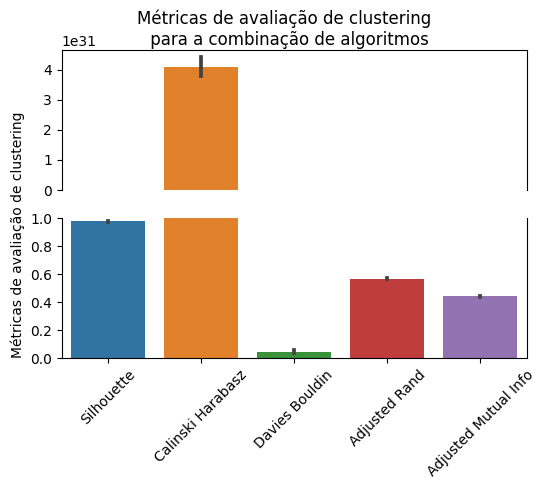

In [98]:
# Gráfico comparativo das métricas de avaliação
fig, ax = plt.subplots(2, 1, figsize=(6, 4))

plt.suptitle("Métricas de avaliação de clustering \n para a combinação de algoritmos")

p = sns.barplot(df_metricas, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)

q = sns.barplot(df_metricas, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.spines["top"].set_visible(False)

plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

In [100]:
# Agrupando os resultados das métricas de avaliação de clustering para os três
# algoritmos, com multi-index
df_metricas = pd.concat(
    [
        df_metricas_repeti_valid_kmeans,
        df_metricas_repeti_valid_dbscan,
        df_metricas_repeti_valid_agg,
    ],
    axis=1,
    keys=["kmeans", "dbscan", "agglomerative"],
)
df_metricas.head()

kmeans                                                 \
  Silhouette Calinski Harabasz Davies Bouldin Adjusted Rand   
0        1.0      6.161188e+31            0.0         0.577   
1        1.0      6.161188e+31            0.0         0.577   
2        1.0      6.161188e+31            0.0         0.577   
3        1.0      6.161188e+31            0.0         0.577   
4        1.0      6.161188e+31            0.0         0.577   

                                     dbscan                                   \
  Adjusted Mutual Info algoritmo Silhouette Calinski Harabasz Davies Bouldin   
0                0.451    kmeans        1.0      6.161188e+31            0.0   
1                0.451    kmeans        1.0      6.161188e+31            0.0   
2                0.451    kmeans        1.0      6.161188e+31            0.0   
3                0.451    kmeans        1.0      6.161188e+31            0.0   
4                0.451    kmeans        1.0      6.161188e+31            0.0   

                                               agglomerative  \
  Adjusted Rand Adjusted Mutual Info algoritmo    Silhouette   
0         0.577                0.451    dbscan         0.926   
1         0.577                0.451    dbscan         0.926   
2         0.577                0.451    dbscan         0.926   
3         0.577                0.451    dbscan         0.926   
4         0.577                0.451    dbscan         0.926   

                                                                       \
  Calinski Harabasz Davies Bouldin Adjusted Rand Adjusted Mutual Info   
0          1244.682          0.139         0.545                 0.42   
1          1244.682          0.139         0.545                 0.42   
2          1244.682          0.139         0.545                 0.42   
3          1244.682          0.139         0.545                 0.42   
4          1244.682          0.139         0.545                 0.42   

             
  algoritmo  
0       agg  
1       agg  
2       agg  
3       agg  
4       agg

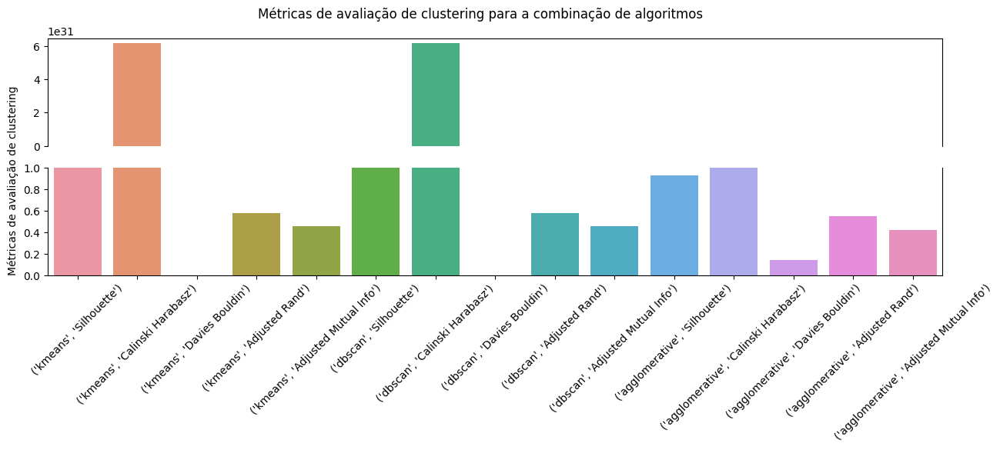

In [101]:
# Gráfico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index
fig, ax = plt.subplots(2, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a combinação de algoritmos")

p = sns.barplot(df_metricas, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)

q = sns.barplot(df_metricas, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.spines["top"].set_visible(False)
plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

In [102]:
def editar_df(df: pd.DataFrame, modelo: str) -> pd.DataFrame:
    """
    Função para editar o dataframe de métricas de avaliação de clustering
    para cada algoritmo, de forma a facilitar a análise comparativa entre
    eles.
        Parametros:
        -----------
            df: pd.DataFrame
                Dataframe de métricas de avaliação de clustering para
                cada algoritmo.
            modelo: str
                Nome do algoritmo de clustering.
        Retorna:
            pd.DataFrame
    """
    colunas = {0: "valores", "index": "metricas"}
    retorno = (
        df.select_dtypes(include="number")
        .median()
        .to_frame()
        .reset_index()
        .rename(columns=colunas)
        .assign(modelo=modelo)
    )
    return retorno

In [103]:
# Agrupando os resultados das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas

df_metricas = pd.concat(
    (
        editar_df(df=df_metricas_repeti_valid_kmeans, modelo="K-means"),
        editar_df(df=df_metricas_repeti_valid_dbscan, modelo="DBSCAN"),
        editar_df(df=df_metricas_repeti_valid_agg, modelo="Agglomerative"),
    )
)
df_metricas

,metricas,valores,modelo
0,Silhouette,1.000000e+00,K-means
1,Calinski Harabasz,6.161188e+31,K-means
2,Davies Bouldin,0.000000e+00,K-means
3,Adjusted Rand,5.770000e-01,K-means
4,Adjusted Mutual Info,4.510000e-01,K-means
0,Silhouette,1.000000e+00,DBSCAN
1,Calinski Harabasz,6.161188e+31,DBSCAN
2,Davies Bouldin,0.000000e+00,DBSCAN
3,Adjusted Rand,5.770000e-01,DBSCAN
4,Adjusted Mutual Info,4.510000e-01,DBSCAN


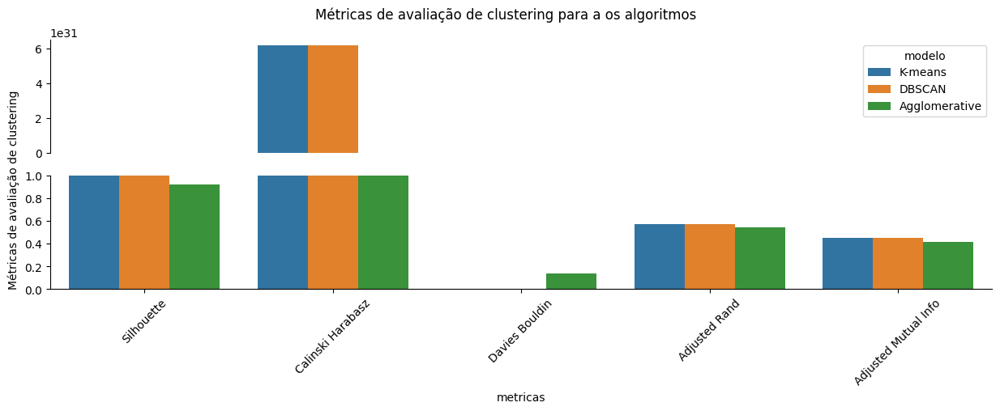

In [104]:
# Grafico comparativo das métricas de avaliação de clustering para os três
# algoritmos, com multi-index, e calculando a mediana das métricas
fig, ax = plt.subplots(2, 1, figsize=(15, 4))
plt.suptitle("Métricas de avaliação de clustering para a os algoritmos")
p = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[0])
plt.xticks(rotation=45)
plt.ylim(100, 700)
p.set(xlabel=None, ylabel=None)
p.set_xticks([])
p.spines["bottom"].set_visible(False)
p.spines[["top", "right"]].set_visible(False)

q = sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas, ax=ax[1])
plt.xticks(rotation=45)
plt.ylim(0, 1)
q.get_legend().remove()
q.spines[["top", "right"]].set_visible(False)
plt.ylabel("Métricas de avaliação de clustering", loc="bottom")

plt.show()

# Testes

## K-means

In [106]:
bivariadas =  [
        ['n_tetraciclina', 'n_polimixinas'],
        ['n_tetraciclina', 'n_degradacao_aromaticos'],
        ['n_polimixinas', 'n_degradacao_aromaticos'],
        ['n_virulencia_clinica', 'n_ilha_AbaR']
]


In [107]:
#Testando os modelos K-means
resultados = {}
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="kmeans")
    resultados[f"K-means: {i}/{j}"] = cluster.testar_modelo(
        best_param={"n_clusters": 3, "init": "k-means++", "n_init": 10},
        df_test=df_test,
    )

n_tetraciclina n_polimixinas ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUSTERS
Frequências Esperadas na Validação (Treino): 
[51.14285714 44.14285714  4.71428571]
Frequências Observadas na Validação:
       [46 52  2]
--------------------------------------------------
Estatística Qui-Quadrado (χ²): 3.4784
p-valor:                        0.1757
--------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
--------------------------------------------------
Adjusted Rand Index (ARI) entre modelo de Treino e modelo da Validação: 0.9129 (ARI próximo de 1.0 indica que a partição geométrica gerada é virtualmente idêntica)
n_tetraciclina n_degradacao_aromaticos ----------------------------------------------------------------------------------------------------
 RESULTADOS DA ANÁLISE DE COMPARAÇÃO DE CLUST

## DBSCAN

In [108]:
#Testando os modelos de DBSCAN
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="dbscan")
    resultados[f"DBSCAN: {i}/{j}"] = cluster.testar_modelo(
        best_param={"eps": 0.5, "min_samples": 10, "metric": "euclidean"},
        df_test=df_test,
    )

n_tetraciclina n_polimixinas ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:       
[0 1 2 3]
Frequências Esperadas na Validação:     
[44.14 47.43  4.71  3.71]
Frequências Observadas na Validação:    
[52 43  2  3]
-------------------------------------------------------
Estatística Qui-Quadrado (χ²): 3.5122
p-valor:                        0.3192
-------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters
na validação É IGUAL à do treino (p > 0.05).
-------------------------------------------------------
Adjusted Rand Index (ARI) entre predição e DBSCAN direto na Validação: 0.9976
n_tetraciclina n_degradacao_aromaticos ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO DE CLUSTERS (DBSCAN)
Clusters identificados no Treino:    

## Agrupamento Hierarquico

In [109]:
#Testando os modelos Agrupamento Hierarquico
for bivaria in bivariadas:
    i = bivaria[0]
    j = bivaria[1]
    print(i, j, "-" * 100)

    cluster = Clustering(c1=i, c2=j, df=df_train, modelo="agglomerative")
    resultados[f"Agg: {i}/{j}"] = cluster.testar_modelo(
        best_param={"n_clusters": 2, "metric": "euclidean", "linkage": "average"},
        df_test=df_test,
    )

n_tetraciclina n_polimixinas ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Frequências Esperadas na Validação:  
[47.86 52.14]
Frequências Observadas na Validação:  
[55 45]
------------------------------------------------------------
Estatística Qui-Quadrado (χ²): 2.0446
p-valor:                        0.1527
------------------------------------------------------------
Conclusão: Não rejeitamos H0. A distribuição dos clusters na validação É IGUAL à do treino (p > 0.05).
------------------------------------------------------------
Adjusted Rand Index (ARI) entre projeção e agrupamento direto: 0.8081
n_tetraciclina n_degradacao_aromaticos ----------------------------------------------------------------------------------------------------
 RESULTADOS DA COMPARAÇÃO (AGGLOMERATIVE CLUSTERING)
Clusters no Treino:                  
[0 1]
Freq

In [110]:
resultados

{'K-means: n_tetraciclina/n_polimixinas': True,
 'K-means: n_tetraciclina/n_degradacao_aromaticos': True,
 'K-means: n_polimixinas/n_degradacao_aromaticos': True,
 'K-means: n_virulencia_clinica/n_ilha_AbaR': True,
 'DBSCAN: n_tetraciclina/n_polimixinas': True,
 'DBSCAN: n_tetraciclina/n_degradacao_aromaticos': True,
 'DBSCAN: n_polimixinas/n_degradacao_aromaticos': True,
 'DBSCAN: n_virulencia_clinica/n_ilha_AbaR': True,
 'Agg: n_tetraciclina/n_polimixinas': True,
 'Agg: n_tetraciclina/n_degradacao_aromaticos': True,
 'Agg: n_polimixinas/n_degradacao_aromaticos': True,
 'Agg: n_virulencia_clinica/n_ilha_AbaR': True}